# Compare masks to protein markers

        CosMx IF
        CosMX masks

        Xenium IMC
        Xenium masks

This notebook intends to provide a Quantitative Validation of Compartment Masks. For this,  we align GRIDGENE-generated cancer and stroma masks across CosMx and Xenium platforms and alignment with reference images. (e.g., IoU, Dice) comparing these masks to orthogonal ground-truth annotations from histopathology or protein staining. 

In [1]:
%load_ext autoreload

import os 
import sys
import time
import logging
import re
from tqdm import tqdm
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from natsort import natsorted

import cv2
import numpy as np
from PIL import Image
import tifffile as tiff
import copy 
import random
from natsort import natsorted
import sys
from pathlib import Path

# Add GRIDGENE root to path
# You need to go up 2 levels
gridgene_root = Path.cwd().parent.parent  # analyses/quantification -> analyses -> GRIDGENE
sys.path.insert(0, str(gridgene_root))

print(f"Added to path: {gridgene_root}")
print(f"gridgene package location: {gridgene_root / 'gridgene'}")
from gridgene import get_arrays as ga
from gridgene import contours 
from gridgene import get_masks

Added to path: /home/martinha/PycharmProjects/phd/GRIDGENE
gridgene package location: /home/martinha/PycharmProjects/phd/GRIDGENE/gridgene


In [2]:
# define the logger :  can be None, and is set to INFO
# Custom logger setup
logger = logging.getLogger('contour_logger')
handler = logging.StreamHandler()
formatter = logging.Formatter('%(asctime)s - %(name)s - %(levelname)s - %(message)s')
handler.setFormatter(formatter)
logger.addHandler(handler)
logger.setLevel(logging.INFO)

Reviewer 1 - Gap 1 - Lack of Quantitative Validation of Compartment Masks: While GRIDGENE-generated cancer and stroma masks are visually coherent across CosMx and Xenium platforms and align with reference images, the study does not provide quantitative metrics (e.g., IoU, Dice) comparing these masks to orthogonal ground-truth annotations from histopathology or protein staining. Without such validation, biological relevance is assumed rather than demonstrated, and the accuracy of compartment boundaries remains unverified. 



In [3]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tifffile
import cv2
from tqdm import tqdm

# Add GRIDGENE to path
gridgene_root = Path.cwd().parent.parent
sys.path.insert(0, str(gridgene_root))

# Import GRIDGENE modules
from gridgene import get_arrays as ga
from gridgene import contours, get_masks

# Import quantification modules
sys.path.append(str(Path.cwd().parent / 'scripts'))
from scripts.preprocessing import preprocess_if_image, register_masks_to_image
from scripts.metrics import calculate_overlap_metrics, calculate_enrichment

print("✓ Imports successful")
print(f"Working directory: {Path.cwd()}")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
✓ Imports successful
Working directory: /home/martinha/PycharmProjects/phd/GRIDGENE/analyses/quantitative_validation


In [4]:
# Cell 3: Helper Functions
"""
Visualization and utility functions
"""

def plot_mask_comparison(gridgene_tumor, gridgene_stroma, 
                        ref_tumor, ref_stroma, 
                        if_image=None, 
                        sample_name="Sample"):
    """
    Create a comprehensive comparison plot
    """
    fig, axes = plt.subplots(2, 3, figsize=(18, 12))
    
    # Row 1: GRIDGENE masks
    axes[0, 0].imshow(gridgene_tumor, cmap='Reds', alpha=0.7)
    axes[0, 0].set_title('GRIDGENE Tumor Mask')
    axes[0, 0].axis('off')
    
    axes[0, 1].imshow(gridgene_stroma, cmap='Blues', alpha=0.7)
    axes[0, 1].set_title('GRIDGENE Stroma Mask')
    axes[0, 1].axis('off')
    
    # Combined GRIDGENE
    combined_gridgene = np.zeros((*gridgene_tumor.shape, 3))
    combined_gridgene[gridgene_tumor > 0] = [1, 0.5, 0]  # Orange for tumor
    combined_gridgene[gridgene_stroma > 0] = [0, 0.5, 1]  # Blue for stroma
    axes[0, 2].imshow(combined_gridgene)
    axes[0, 2].set_title('GRIDGENE Combined')
    axes[0, 2].axis('off')
    
    # Row 2: Reference masks
    axes[1, 0].imshow(ref_tumor, cmap='Reds', alpha=0.7)
    axes[1, 0].set_title('Reference Tumor (IF)')
    axes[1, 0].axis('off')
    
    axes[1, 1].imshow(ref_stroma, cmap='Greens', alpha=0.7)
    axes[1, 1].set_title('Reference Stroma (IF)')
    axes[1, 1].axis('off')
    
    # Overlay on IF if provided
    if if_image is not None:
        # Create contours
        contours_gg_tum, _ = cv2.findContours(gridgene_tumor.astype(np.uint8), 
                                              cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        contours_gg_str, _ = cv2.findContours(gridgene_stroma.astype(np.uint8), 
                                              cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        
        overlay = if_image.copy()
        if overlay.max() <= 1.0:
            overlay = (overlay * 255).astype(np.uint8)
        
        cv2.drawContours(overlay, contours_gg_tum, -1, (255, 255, 0), 2)  # Yellow
        cv2.drawContours(overlay, contours_gg_str, -1, (0, 255, 255), 2)  # Cyan
        
        axes[1, 2].imshow(overlay)
        axes[1, 2].set_title('GRIDGENE Contours on IF')
        axes[1, 2].axis('off')
    
    plt.suptitle(f'{sample_name} - Mask Comparison', fontsize=16, y=0.98)
    plt.tight_layout()
    
    return fig


def plot_metrics_bar(metrics_dict, sample_name="Sample"):
    """
    Create bar plot of metrics
    """
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Tumor metrics
    tumor_metrics = {
        'Dice': metrics_dict['dice_tumor'],
        'IoU': metrics_dict['iou_tumor'],
        'Precision': metrics_dict['precision_tumor'],
        'Recall': metrics_dict['recall_tumor'],
        'F1': metrics_dict['f1_tumor']
    }
    
    axes[0].bar(tumor_metrics.keys(), tumor_metrics.values(), color='coral')
    axes[0].set_ylim([0, 1])
    axes[0].set_ylabel('Score')
    axes[0].set_title('Tumor Mask Metrics')
    axes[0].axhline(y=0.7, color='gray', linestyle='--', alpha=0.5)
    
    # Stroma metrics
    stroma_metrics = {
        'Dice': metrics_dict['dice_stroma'],
        'IoU': metrics_dict['iou_stroma'],
        'Precision': metrics_dict['precision_stroma'],
        'Recall': metrics_dict['recall_stroma'],
        'F1': metrics_dict['f1_stroma']
    }
    
    axes[1].bar(stroma_metrics.keys(), stroma_metrics.values(), color='skyblue')
    axes[1].set_ylim([0, 1])
    axes[1].set_ylabel('Score')
    axes[1].set_title('Stroma Mask Metrics')
    axes[1].axhline(y=0.7, color='gray', linestyle='--', alpha=0.5)
    
    plt.suptitle(f'{sample_name} - Quantitative Metrics', fontsize=14)
    plt.tight_layout()
    
    return fig

print("✓ Helper functions defined")

✓ Helper functions defined


In [5]:
# Cell 4: GRIDGENE Pipeline Function
"""
Wrapper for GRIDGENE mask generation
"""

def do_cosmx_pipeline(file_csv, target_tum, 
                     kernel_size_tum, density_th_tum, min_area_th_tum,
                     kernel_size_empty, density_th_empty, min_area_th_empty,
                     plot=False):
    """
    Generate GRIDGENE masks from CosMx CSV file
    
    Returns:
    --------
    tuple: (mask_tumor, mask_stroma, height, width)
    """
    
    # Load and prepare data
    df_total = pd.read_csv(file_csv)
    df_total['X'] = (round(df_total['x'])).astype(int)
    df_total['Y'] = (round(df_total['y'])).astype(int)
    
    height = max(df_total['X']) + 1
    width = max(df_total['Y']) + 1
    
    target_dict_total = {target: index for index, target in enumerate(df_total['target'].unique())}
    
    # Create array
    array_total = ga.transform_df_to_array(
        df=df_total, 
        target_dict=target_dict_total, 
        array_shape=(height, width, len(target_dict_total))
    ).astype(np.int8)
    
    # Subset for tumor markers
    df_subset_tum, array_subset_tum, target_indices_subset_tum = ga.get_subset_arrays(
        df_total, array_total, target_dict_total,
        target_list=target_tum, target_col='target'
    )
    
    # Tumor contours
    CTum = contours.ConvolutionContours(array_subset_tum, contour_name='tum')
    CTum.get_conv_sum(kernel_size=kernel_size_tum, kernel_shape='square')
    CTum.contours_from_sum(
        density_threshold=density_th_tum,
        min_area_threshold=min_area_th_tum,
        directionality='higher'
    )
    
    # Empty region contours
    CEmpty = contours.ConvolutionContours(array_total, contour_name='empty')
    CEmpty.get_conv_sum(kernel_size=kernel_size_empty, kernel_shape='square')
    CEmpty.contours_from_sum(
        density_threshold=density_th_empty,
        min_area_threshold=min_area_th_empty,
        directionality='lower'
    )
    
    # Create masks
    GM = get_masks.GetMasks(image_shape=(height, width))
    
    mask_empty = GM.create_mask(CEmpty.contours)
    mask_tum = GM.create_mask(CTum.contours)
    mask_tum = GM.fill_holes(mask_tum)
    mask_stroma = GM.subtract_masks(
        np.ones((height, width), dtype=np.uint8), 
        mask_tum, 
        mask_empty
    )
    mask_stroma = GM.filter_binary_mask_by_area(mask_stroma, min_area=700)
    
    # Optional plotting
    if plot:
        fig, axs = plt.subplots(1, 3, figsize=(18, 6))
        
        CTum.plot_contours_scatter(
            path=None, show=False, s=0.05, alpha=0.5, linewidth=1,
            c_points='blue', c_contours='red', ax=axs[0]
        )
        axs[0].set_title('Tumor Contours')
        
        CEmpty.plot_contours_scatter(
            path=None, show=False, s=0.05, alpha=0.5, linewidth=1,
            c_points='blue', c_contours='red', ax=axs[1]
        )
        axs[1].set_title('Empty Region Contours')
        
        GM.plot_masks(
            masks=[mask_stroma, mask_tum], 
            mask_names=['Stroma', 'Tumor'],
            background_color=(1, 1, 1), 
            mask_colors={'Stroma': (65, 105, 225), 'Tumor': (255, 165, 0)},
            path=None, show=False, ax=axs[2]
        )
        axs[2].set_title('Final Masks')
        
        plt.tight_layout()
        plt.show()
    
    return mask_tum, mask_stroma, mask_empty, height, width  # Added mask_empty

print("✓ GRIDGENE pipeline function defined")

✓ GRIDGENE pipeline function defined


## CosMx 
Map CosMx cohort with the IF data

CosMx paths

In [6]:
import tifffile


In [7]:
import os
from natsort import natsorted
import copy
cosmx_path_s0 =  '/home/martinha/PycharmProjects/phd/spatial_transcriptomics/cosmx_data/S0/S0/20230628_151317_S4/AnalysisResults/iz38iruwno'

folder_names_s0 = [folder_name for folder_name in os.listdir(cosmx_path_s0) if
                os.path.isdir(os.path.join(cosmx_path_s0, folder_name))]

target_files_s0 = [
    os.path.join(cosmx_path_s0, folder, file)
    for folder in os.listdir(cosmx_path_s0)
    if os.path.isdir(os.path.join(cosmx_path_s0, folder))
    for file in os.listdir(os.path.join(cosmx_path_s0, folder))
    if '__target_call_coord.csv' in file
]

files_names = natsorted(target_files_s0)
files_cosmx = copy.deepcopy(files_names)


# param cancer
target_tum =  ['EPCAM',  'KRT19', 'KRT8', 'KRT18','KRT17','CEACAM6','SPINK1', 'CD24', 'S100A6','RPL37','S100P',]  
density_th_tum = 40    
min_area_th_tum =  1000 
kernel_size_tum = 80

# param empty
density_th_empty = 140
min_area_th_empty = 2000 
kernel_size_empty = 80

Testing with:
  CSV: /home/martinha/PycharmProjects/phd/spatial_transcriptomics/cosmx_data/S0/S0/20230628_151317_S4/AnalysisResults/iz38iruwno/FOV001/Run_69de8227-1a7b-40ee-ba46-0ea99a7c59f4_FOV001__target_call_coord.csv
  IF:  /home/martinha/PycharmProjects/phd/spatial_transcriptomics/GRIDGEN/case_studies/composites/20230628_151317_S4_C902_P99_N99_F001_composite.tiff

1. Generating GRIDGENE masks...


2026-01-03 21:53:59,186 - gridgene.contours.tum - INFO - Initialized GetContour
2026-01-03 21:53:59,662 - gridgene.contours.tum - INFO - get_conv_sum took 0.4757 seconds
2026-01-03 21:53:59,977 - gridgene.contours.tum - INFO - Number of contours after filtering no counts: 38
2026-01-03 21:53:59,978 - gridgene.contours.tum - INFO - contours_from_sum took 0.3150 seconds
2026-01-03 21:53:59,978 - gridgene.contours.empty - INFO - Initialized GetContour
2026-01-03 21:54:08,794 - gridgene.contours.empty - INFO - get_conv_sum took 8.8153 seconds
2026-01-03 21:54:17,405 - gridgene.contours.empty - INFO - Number of contours after filtering no counts: 35
2026-01-03 21:54:17,406 - gridgene.contours.empty - INFO - contours_from_sum took 8.6118 seconds
2026-01-03 21:54:17,406 - gridgene.get_masks.GetMasks - INFO - Initialized GetMasks
2026-01-03 21:54:17,429 - gridgene.get_masks.GetMasks - INFO - Subtracted masks from base mask.


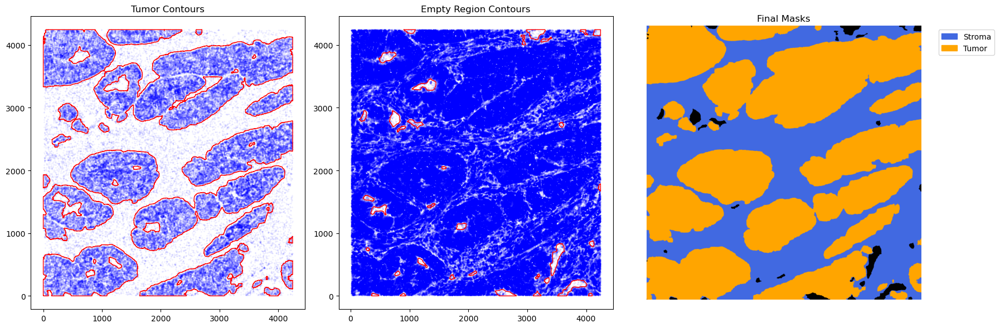

   Tumor mask: 10394493 pixels
   Stroma mask: 7337499 pixels
   Empty mask: 422860 pixels


In [17]:
# Cell 5: SINGLE FOV TEST
"""
Test on a single FOV to validate the workflow
"""

# Define your test file pair
test_csv = files_names[0]   # 5
test_if = '/home/martinha/PycharmProjects/phd/spatial_transcriptomics/GRIDGEN/case_studies/composites/20230628_151317_S4_C902_P99_N99_F001_composite.tiff'

print(f"Testing with:")
print(f"  CSV: {test_csv}")
print(f"  IF:  {test_if}")

# Step 1: Generate GRIDGENE masks
print("\n1. Generating GRIDGENE masks...")
mask_tumor_gridgene, mask_stroma_gridgene, mask_empty_gridgene,height, width = do_cosmx_pipeline(  # ADDED mask_empty_gg
    test_csv, 
    target_tum=target_tum,
    kernel_size_tum=kernel_size_tum,
    density_th_tum=density_th_tum,
    min_area_th_tum=min_area_th_tum,
    kernel_size_empty=kernel_size_empty,
    density_th_empty=density_th_empty,
    min_area_th_empty=min_area_th_empty,
    plot=True
)

print(f"   Tumor mask: {mask_tumor_gg.sum()} pixels")
print(f"   Stroma mask: {mask_stroma_gg.sum()} pixels")
print(f"   Empty mask: {mask_empty_gg.sum()} pixels")  # ADDED

Check how the IF image looks like

The original IF images were clean/preprocessed with PENGUIN. importantly this does not mean that they can be used directly as masks, do to the separation of membrane / nucleus.  Lets see how the IF images look like 

In [9]:
path_if =  "/home/martinha/PycharmProjects/phd/spatial_transcriptomics/GRIDGEN/case_studies/PENGUINcomposites/"
test_if = os.path.join(path_if, "20230628_151317_S4_C902_P99_N99_F001_composite.tiff" )

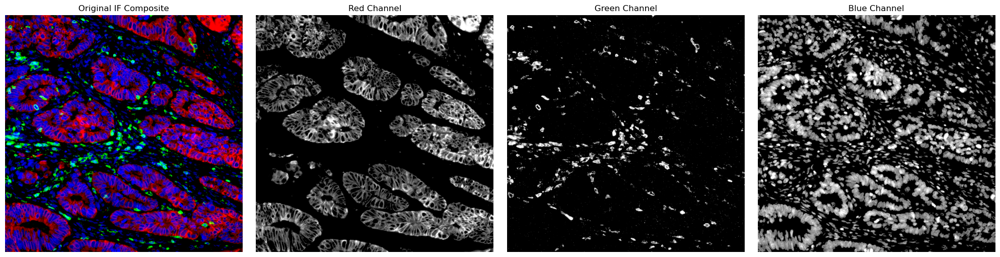

In [10]:
# Load the IF image
if_image = tifffile.imread(test_if)
if_image = np.moveaxis(if_image, 0, -1)  # (3, H, W) -> (H, W, 3)

# Normalize to uint8 if needed
if if_image.max() <= 1.0:
    if_image = (if_image * 255).astype(np.uint8)

# Create figure with 4 subplots
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

# Display original composite
axes[0].imshow(if_image)
axes[0].set_title('Original IF Composite')
axes[0].axis('off')

# Display Red channel
axes[1].imshow(if_image[:, :, 0], cmap = 'gray')
axes[1].set_title('Red Channel')
axes[1].axis('off')

# Display Green channel
axes[2].imshow(if_image[:, :, 1], cmap = 'gray')
axes[2].set_title('Green Channel')
axes[2].axis('off')

# Display Blue channel
axes[3].imshow(if_image[:, :, 2], cmap = 'gray')
axes[3].set_title('Blue Channel')
axes[3].axis('off')

plt.tight_layout()
plt.show()

for the Red channel we will incorporate the blue objects touching and remove very small objects
remove the nuclei assigned to the red. join blue + green. 


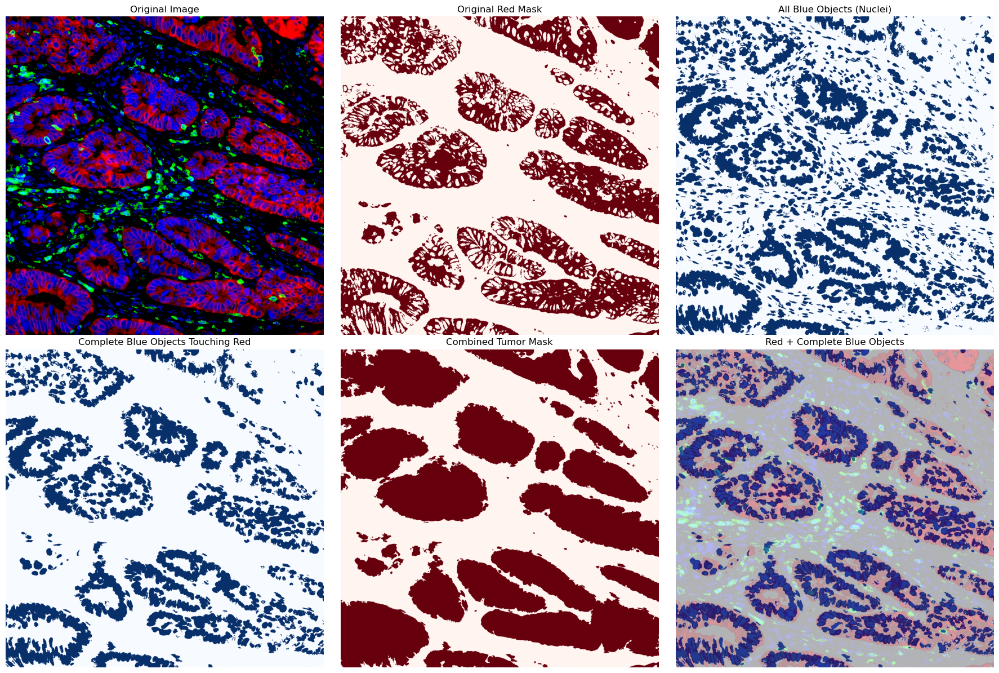

Original red coverage: 35.59%
Number of blue objects captured: 425
Blue pixels captured: 4952760
Combined tumor mask coverage: 52.45%
Additional coverage from blue: 16.86%


In [13]:
from skimage import morphology
from scipy import ndimage

def add_complete_blue_objects_touching_red(red_mask, blue_channel):
    """
    Add COMPLETE blue objects (nuclei) that touch or overlap with red mask
    If any part of a blue object touches red, include the entire blue object
    """
    
    # Create blue mask (nuclei)
    blue_threshold = np.percentile(blue_channel[blue_channel > 0], 20)
    blue_mask = blue_channel > blue_threshold
    blue_mask = morphology.remove_small_objects(blue_mask, min_size=50)
    
    # Label individual blue objects (each nucleus gets a unique ID)
    blue_labeled, num_blue_objects = ndimage.label(blue_mask)
    
    # Slightly dilate red to catch nuclei very close to red
    red_dilated = morphology.binary_dilation(red_mask, morphology.disk(5))
    
    # Find which blue objects touch the (dilated) red mask
    blue_objects_to_keep = np.zeros_like(blue_mask, dtype=bool)
    
    for object_id in range(1, num_blue_objects + 1):
        # Get this specific blue object
        current_object = (blue_labeled == object_id)
        
        # Check if ANY part of this object overlaps with red
        if np.any(current_object & red_dilated):
            # If yes, keep the ENTIRE object
            blue_objects_to_keep |= current_object
    
    # Combine red with complete blue objects
    combined_mask = red_mask | blue_objects_to_keep
    
    return (combined_mask.astype(np.uint8), 
            blue_mask.astype(np.uint8), 
            blue_objects_to_keep.astype(np.uint8))


# Visualize
penguin_img = tifffile.imread(test_if)
penguin_img = np.moveaxis(penguin_img, 0, -1)

red_channel = penguin_img[:, :, 0]
blue_channel = penguin_img[:, :, 2]

# Create initial red mask
red_threshold = np.percentile(red_channel[red_channel > 0], 10)
red_mask = red_channel > red_threshold
red_mask = morphology.remove_small_objects(red_mask, min_size=100)
# red_mask = morphology.binary_closing(red_mask, morphology.disk(25))
# red_mask = ndimage.binary_fill_holes(red_mask)

# Add complete blue objects that touch red
combined_tumor_mask, all_blue, blue_captured = add_complete_blue_objects_touching_red(red_mask, blue_channel)
combined_tumor_mask = ndimage.binary_fill_holes(combined_tumor_mask)

# Visualize
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# Top row
axes[0, 0].imshow(penguin_img)
axes[0, 0].set_title('Original Image')
axes[0, 0].axis('off')

axes[0, 1].imshow(red_mask, cmap='Reds')
axes[0, 1].set_title('Original Red Mask')
axes[0, 1].axis('off')

axes[0, 2].imshow(all_blue, cmap='Blues')
axes[0, 2].set_title('All Blue Objects (Nuclei)')
axes[0, 2].axis('off')

# Bottom row
axes[1, 0].imshow(blue_captured, cmap='Blues')
axes[1, 0].set_title('Complete Blue Objects Touching Red')
axes[1, 0].axis('off')

axes[1, 1].imshow(combined_tumor_mask, cmap='Reds')
axes[1, 1].set_title('Combined Tumor Mask')
axes[1, 1].axis('off')

axes[1, 2].imshow(penguin_img)
axes[1, 2].imshow(red_mask, alpha=0.3, cmap='Reds')
axes[1, 2].imshow(blue_captured, alpha=0.6, cmap='Blues')
axes[1, 2].set_title('Red + Complete Blue Objects')
axes[1, 2].axis('off')

plt.tight_layout()
plt.show()

print(f"Original red coverage: {red_mask.sum() / red_mask.size * 100:.2f}%")
print(f"Number of blue objects captured: {np.unique(ndimage.label(blue_captured)[0]).size - 1}")
print(f"Blue pixels captured: {blue_captured.sum()}")
print(f"Combined tumor mask coverage: {combined_tumor_mask.sum() / combined_tumor_mask.size * 100:.2f}%")
print(f"Additional coverage from blue: {(combined_tumor_mask.sum() - red_mask.sum()) / red_mask.size * 100:.2f}%")

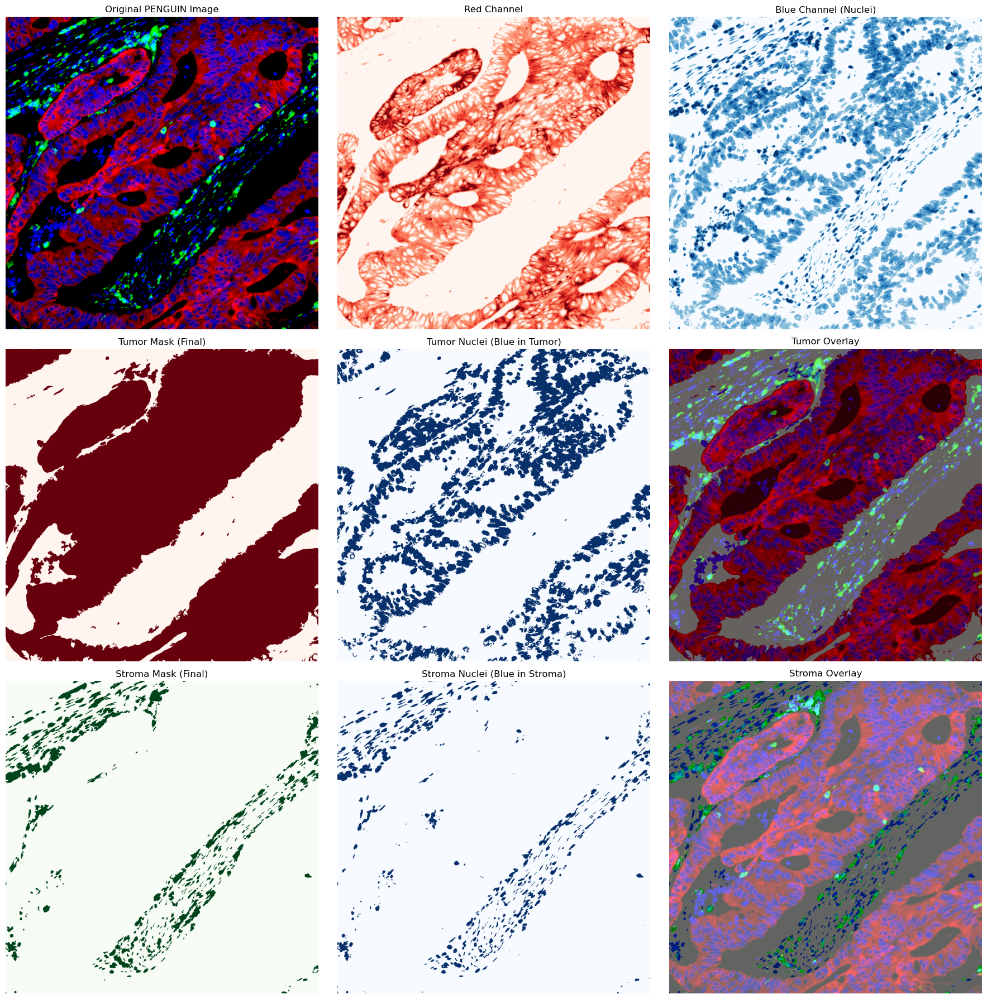

Tumor coverage: 64.23%
  - Tumor nuclei objects: 588
Stroma coverage: 6.38%
  - Stroma nuclei objects: 513
Empty coverage: 29.39%


In [18]:
from scipy import ndimage
from skimage import morphology
import numpy as np

def create_tumor_and_stroma_masks(penguin_img):
    """
    Create tumor and stroma masks:
    - Tumor = red + complete blue objects touching red (with small holes filled)
    - Stroma = green + complete blue objects NOT touching red
    """
    
    # Extract channels
    red_channel = penguin_img[:, :, 0]
    green_channel = penguin_img[:, :, 1]
    blue_channel = penguin_img[:, :, 2]
    
    # ===== STEP 1: Create initial red mask =====
    red_threshold = np.percentile(red_channel[red_channel > 0], 10)
    red_mask = red_channel > red_threshold
    red_mask = morphology.remove_small_objects(red_mask, min_size=100)
    # NOT using aggressive closing - keeping it cleaner
    
    # ===== STEP 2: Create blue mask and label objects =====
    blue_threshold = np.percentile(blue_channel[blue_channel > 0], 20)
    blue_mask = blue_channel > blue_threshold
    blue_mask = morphology.remove_small_objects(blue_mask, min_size=50)
    
    # Label individual blue objects
    blue_labeled, num_blue_objects = ndimage.label(blue_mask)
    
    # ===== STEP 3: Find blue objects touching red =====
    red_dilated = morphology.binary_dilation(red_mask, morphology.disk(5))
    
    blue_in_tumor = np.zeros_like(blue_mask, dtype=bool)
    blue_in_stroma = np.zeros_like(blue_mask, dtype=bool)
    
    for object_id in range(1, num_blue_objects + 1):
        current_object = (blue_labeled == object_id)
        
        if np.any(current_object & red_dilated):
            # This blue object touches red -> goes to tumor
            blue_in_tumor |= current_object
        else:
            # This blue object doesn't touch red -> goes to stroma
            blue_in_stroma |= current_object
    
    # ===== STEP 4: Create TUMOR mask (red + blue touching red) =====
    tumor_mask = red_mask | blue_in_tumor
    
    # Fill small holes in tumor mask
    tumor_mask = ndimage.binary_fill_holes(tumor_mask)
    
    # Optional: remove very small isolated regions
    tumor_mask = morphology.remove_small_objects(tumor_mask, min_size=200)
    
    # ===== STEP 5: Create STROMA mask (green + blue NOT touching red) =====
    green_threshold = np.percentile(green_channel[green_channel > 0], 10)
    green_mask = green_channel > green_threshold
    green_mask = morphology.binary_opening(green_mask, morphology.disk(3))
    green_mask = morphology.remove_small_objects(green_mask, min_size=200)
    
    # Combine green with unassigned blue
    stroma_mask = green_mask | blue_in_stroma
    
    # Make sure stroma doesn't overlap with tumor
    stroma_mask = stroma_mask & ~tumor_mask
    
    # Fill holes and clean up stroma
    stroma_mask = ndimage.binary_fill_holes(stroma_mask)
    stroma_mask = morphology.remove_small_objects(stroma_mask, min_size=200)
    
    # ===== STEP 6: Create EMPTY mask =====
    empty_mask = ~(tumor_mask | stroma_mask)
    
    return (tumor_mask.astype(np.uint8),
            stroma_mask.astype(np.uint8),
            empty_mask.astype(np.uint8),
            blue_in_tumor.astype(np.uint8),
            blue_in_stroma.astype(np.uint8))


# Load image
test_penguin = list(Path(path_if).glob('*.tiff'))[0]
penguin_img = tifffile.imread(test_penguin)
penguin_img = np.moveaxis(penguin_img, 0, -1)

# Create all masks
tumor_mask_if, stroma_mask_if, empty_mask_if, blue_in_tumor, blue_in_stroma = create_tumor_and_stroma_masks(penguin_img)

# Visualize
fig, axes = plt.subplots(3, 3, figsize=(18, 18))

# Row 1: Original and channels
axes[0, 0].imshow(penguin_img)
axes[0, 0].set_title('Original PENGUIN Image')
axes[0, 0].axis('off')

axes[0, 1].imshow(penguin_img[:, :, 0], cmap='Reds')
axes[0, 1].set_title('Red Channel')
axes[0, 1].axis('off')

axes[0, 2].imshow(penguin_img[:, :, 2], cmap='Blues')
axes[0, 2].set_title('Blue Channel (Nuclei)')
axes[0, 2].axis('off')

# Row 2: Tumor compartment breakdown
axes[1, 0].imshow(tumor_mask, cmap='Reds')
axes[1, 0].set_title('Tumor Mask (Final)')
axes[1, 0].axis('off')

axes[1, 1].imshow(blue_in_tumor, cmap='Blues')
axes[1, 1].set_title('Tumor Nuclei (Blue in Tumor)')
axes[1, 1].axis('off')

axes[1, 2].imshow(penguin_img)
axes[1, 2].imshow(tumor_mask, alpha=0.4, cmap='Reds')
axes[1, 2].set_title('Tumor Overlay')
axes[1, 2].axis('off')

# Row 3: Stroma compartment breakdown
axes[2, 0].imshow(stroma_mask, cmap='Greens')
axes[2, 0].set_title('Stroma Mask (Final)')
axes[2, 0].axis('off')

axes[2, 1].imshow(blue_in_stroma, cmap='Blues')
axes[2, 1].set_title('Stroma Nuclei (Blue in Stroma)')
axes[2, 1].axis('off')

axes[2, 2].imshow(penguin_img)
axes[2, 2].imshow(stroma_mask, alpha=0.4, cmap='Greens')
axes[2, 2].set_title('Stroma Overlay')
axes[2, 2].axis('off')

plt.tight_layout()
plt.show()

print(f"Tumor coverage: {tumor_mask.sum() / tumor_mask.size * 100:.2f}%")
print(f"  - Tumor nuclei objects: {np.unique(ndimage.label(blue_in_tumor)[0]).size - 1}")
print(f"Stroma coverage: {stroma_mask.sum() / stroma_mask.size * 100:.2f}%")
print(f"  - Stroma nuclei objects: {np.unique(ndimage.label(blue_in_stroma)[0]).size - 1}")
print(f"Empty coverage: {empty_mask.sum() / empty_mask.size * 100:.2f}%")

display the masks

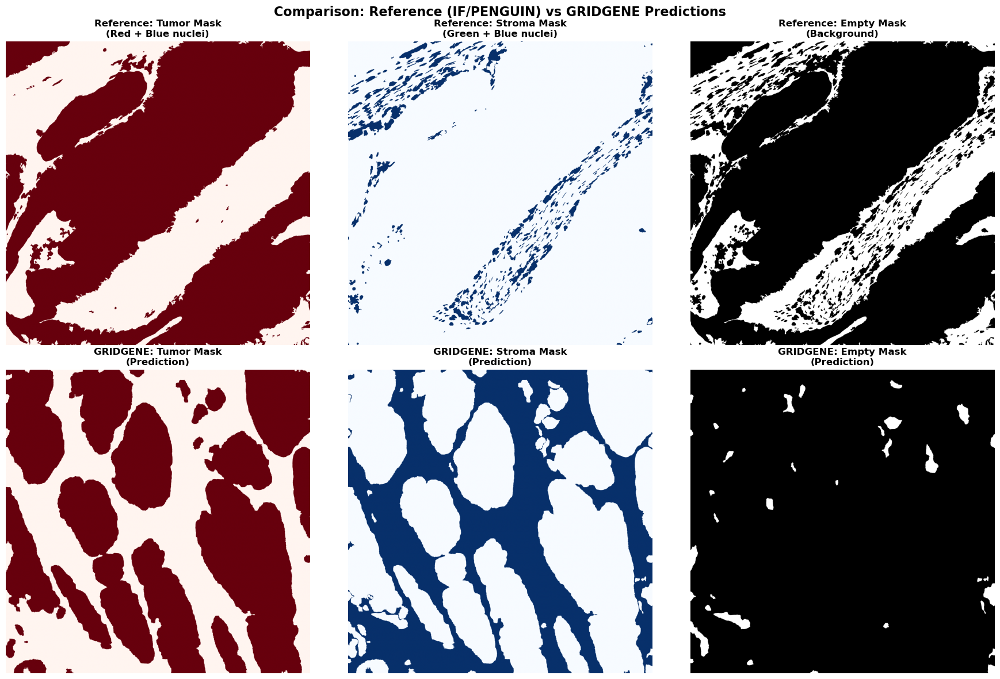

REFERENCE MASKS (IF/PENGUIN):
  Tumor coverage:  64.23%
  Stroma coverage: 6.38%
  Empty coverage:  29.39%

GRIDGENE PREDICTIONS:
  Tumor coverage:  57.66%
  Stroma coverage: 40.70%
  Empty coverage:  2.35%


In [15]:
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# Row 1: Reference masks from IF/PENGUIN
axes[0, 0].imshow(tumor_mask, cmap='Reds')
axes[0, 0].set_title('Reference: Tumor Mask\n(Red + Blue nuclei)', fontsize=12, fontweight='bold')
axes[0, 0].axis('off')

axes[0, 1].imshow(stroma_mask, cmap='Blues')  # Using Blues for stroma
axes[0, 1].set_title('Reference: Stroma Mask\n(Green + Blue nuclei)', fontsize=12, fontweight='bold')
axes[0, 1].axis('off')

axes[0, 2].imshow(empty_mask, cmap='gray')
axes[0, 2].set_title('Reference: Empty Mask\n(Background)', fontsize=12, fontweight='bold')
axes[0, 2].axis('off')

# Row 2: GRIDGENE predictions
axes[1, 0].imshow(mask_tumor_gg, cmap='Reds')
axes[1, 0].set_title('GRIDGENE: Tumor Mask\n(Prediction)', fontsize=12, fontweight='bold')
axes[1, 0].axis('off')

axes[1, 1].imshow(mask_stroma_gg, cmap='Blues')
axes[1, 1].set_title('GRIDGENE: Stroma Mask\n(Prediction)', fontsize=12, fontweight='bold')
axes[1, 1].axis('off')

axes[1, 2].imshow(mask_empty_gg, cmap='gray')
axes[1, 2].set_title('GRIDGENE: Empty Mask\n(Prediction)', fontsize=12, fontweight='bold')
axes[1, 2].axis('off')

plt.suptitle('Comparison: Reference (IF/PENGUIN) vs GRIDGENE Predictions', 
             fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

# Print coverage statistics
print("=" * 60)
print("REFERENCE MASKS (IF/PENGUIN):")
print(f"  Tumor coverage:  {tumor_mask.sum() / tumor_mask.size * 100:.2f}%")
print(f"  Stroma coverage: {stroma_mask.sum() / stroma_mask.size * 100:.2f}%")
print(f"  Empty coverage:  {empty_mask.sum() / empty_mask.size * 100:.2f}%")
print()
print("GRIDGENE PREDICTIONS:")
print(f"  Tumor coverage:  {mask_tumor_gg.sum() / mask_tumor_gg.size * 100:.2f}%")
print(f"  Stroma coverage: {mask_stroma_gg.sum() / mask_stroma_gg.size * 100:.2f}%")
print(f"  Empty coverage:  {mask_empty_gg.sum() / mask_empty_gg.size * 100:.2f}%")
print("=" * 60)

Derive metrics. 
Show disagreement in one image and metrics in one image
Get the metrics for the full cohort 

In [22]:
from skimage.transform import resize

def resize_masks_to_match(mask_gg, mask_ref):
    """
    Resize GRIDGENE mask to match reference mask dimensions
    
    Parameters:
    -----------
    mask_gg : np.ndarray
        GRIDGENE mask (potentially different size)
    mask_ref : np.ndarray
        Reference mask from IF/PENGUIN (target size)
    
    Returns:
    --------
    np.ndarray : Resized GRIDGENE mask
    """
    if mask_gg.shape != mask_ref.shape:
        # Resize GRIDGENE to match reference
        # Use order=0 for nearest neighbor (preserves binary mask)
        mask_gg_resized = resize(mask_gg, mask_ref.shape, 
                                order=0, preserve_range=True, 
                                anti_aliasing=False)
        mask_gg_resized = mask_gg_resized.astype(np.uint8)
        return mask_gg_resized
    return mask_gg


def calculate_segmentation_metrics(reference_mask, predicted_mask, mask_name=""):
    """
    Calculate segmentation metrics comparing reference (ground truth) vs predicted masks
    Handles dimension mismatch automatically
    """
    
    # Ensure masks have the same dimensions
    if reference_mask.shape != predicted_mask.shape:
        print(f"  Note: Resizing {mask_name} mask from {predicted_mask.shape} to {reference_mask.shape}")
        predicted_mask = resize_masks_to_match(predicted_mask, reference_mask)
    
    # Flatten masks for calculation
    ref_flat = reference_mask.flatten().astype(bool)
    pred_flat = predicted_mask.flatten().astype(bool)
    
    # Calculate confusion matrix components
    TP = np.sum(ref_flat & pred_flat)   # True Positive: both agree it's present
    FP = np.sum(~ref_flat & pred_flat)  # False Positive: GRIDGENE says yes, reference says no
    FN = np.sum(ref_flat & ~pred_flat)  # False Negative: reference says yes, GRIDGENE says no
    TN = np.sum(~ref_flat & ~pred_flat) # True Negative: both agree it's absent
    
    # Handle edge cases where masks are completely empty
    if TP + FP + FN == 0:
        return {
            'mask_name': mask_name,
            'dice': 1.0,
            'iou': 1.0,
            'precision': 1.0,
            'recall': 1.0,
            'f1': 1.0,
            'accuracy': 1.0,
            'TP': TP,
            'FP': FP,
            'FN': FN,
            'TN': TN,
            'note': 'Both masks empty'
        }
    
    # Calculate metrics
    dice = (2 * TP) / (2 * TP + FP + FN) if (2 * TP + FP + FN) > 0 else 0.0
    iou = TP / (TP + FP + FN) if (TP + FP + FN) > 0 else 0.0
    precision = TP / (TP + FP) if (TP + FP) > 0 else 0.0
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0.0
    f1 = (2 * precision * recall) / (precision + recall) if (precision + recall) > 0 else 0.0
    accuracy = (TP + TN) / (TP + TN + FP + FN)
    
    return {
        'mask_name': mask_name,
        'dice': dice,
        'iou': iou,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'accuracy': accuracy,
        'TP': TP,
        'FP': FP,
        'FN': FN,
        'TN': TN,
        'reference_shape': reference_mask.shape,
        'predicted_shape': predicted_mask.shape,
        'note': 'OK'
    }


def calculate_all_compartment_metrics(tumor_ref, stroma_ref, empty_ref,
                                     tumor_gg, stroma_gg, empty_gg):
    """
    Calculate metrics for all three compartments
    """
    
    metrics = {
        'tumor': calculate_segmentation_metrics(tumor_ref, tumor_gg, "Tumor"),
        'stroma': calculate_segmentation_metrics(stroma_ref, stroma_gg, "Stroma"),
        'empty': calculate_segmentation_metrics(empty_ref, empty_gg, "Empty")
    }
    
    return metrics


# Test on your current FOV
print(f"Reference shape: {tumor_mask.shape}")
print(f"GRIDGENE shape: {mask_tumor_gg.shape}")
print()

metrics = calculate_all_compartment_metrics(
    mask_tumor_gridgene, mask_stroma_gridgene, mask_empty_gridgene,
    tumor_mask_if, stroma_mask_if, empty_mask_if,
)


# Display results
print("=" * 80)
print("SEGMENTATION METRICS: Reference (IF/PENGUIN) vs GRIDGENE")
print("=" * 80)

for compartment in ['tumor', 'stroma', 'empty']:
    m = metrics[compartment]
    print(f"\n{m['mask_name'].upper()} COMPARTMENT:")
    print(f"  Dice Coefficient: {m['dice']:.4f}")
    print(f"  IoU (Jaccard):    {m['iou']:.4f}")
    print(f"  Precision:        {m['precision']:.4f}")
    print(f"  Recall:           {m['recall']:.4f}")
    print(f"  F1 Score:         {m['f1']:.4f}")
    print(f"  Accuracy:         {m['accuracy']:.4f}")
    print(f"  ---")
    print(f"  True Positives:   {m['TP']:,}")
    print(f"  False Positives:  {m['FP']:,}")
    print(f"  False Negatives:  {m['FN']:,}")

print("=" * 80)


Reference shape: (4256, 4256)
GRIDGENE shape: (4246, 4246)

  Note: Resizing Tumor mask from (4256, 4256) to (4246, 4246)
  Note: Resizing Stroma mask from (4256, 4256) to (4246, 4246)
  Note: Resizing Empty mask from (4256, 4256) to (4246, 4246)
SEGMENTATION METRICS: Reference (IF/PENGUIN) vs GRIDGENE

TUMOR COMPARTMENT:
  Dice Coefficient: 0.5812
  IoU (Jaccard):    0.4097
  Precision:        0.5515
  Recall:           0.6144
  F1 Score:         0.5812
  Accuracy:         0.4896
  ---
  True Positives:   6,386,219
  False Positives:  5,193,783
  False Negatives:  4,008,274

STROMA COMPARTMENT:
  Dice Coefficient: 0.0987
  IoU (Jaccard):    0.0519
  Precision:        0.3639
  Recall:           0.0571
  F1 Score:         0.0987
  Accuracy:         0.5756
  ---
  True Positives:   418,693
  False Positives:  731,833
  False Negatives:  6,918,806

EMPTY COMPARTMENT:
  Dice Coefficient: 0.0304
  IoU (Jaccard):    0.0154
  Precision:        0.0164
  Recall:           0.2055
  F1 Score:    

Generating fast disagreement visualizations...

Creating disagreement maps...
  Maps created, plotting...


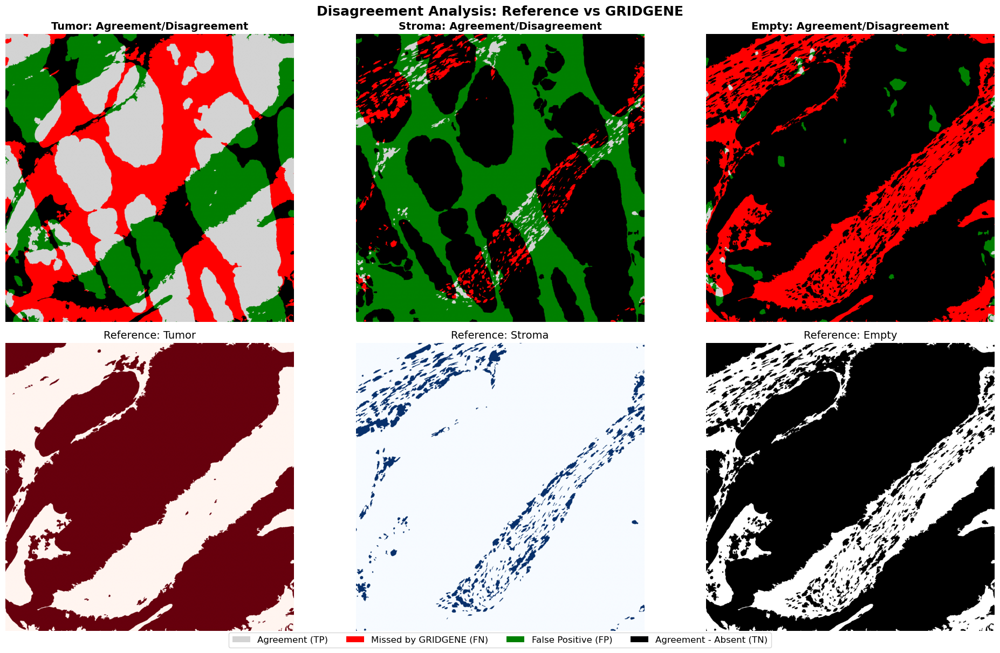

Done!


In [27]:
def create_disagreement_map_fast(reference_mask, predicted_mask):
    """
    Fast disagreement calculation using arithmetic
    
    reference_mask: 0 or 1
    predicted_mask: 0 or 1
    
    Result:
    0: Both say no (TN)
    1: Reference yes, GRIDGENE no (FN) 
    2: GRIDGENE yes, Reference no (FP)
    3: Both say yes (TP)
    """
    # Resize if needed
    if reference_mask.shape != predicted_mask.shape:
        predicted_mask = resize_masks_to_match(predicted_mask, reference_mask)
    
    # Simple arithmetic: ref + 2*pred gives us 4 unique values
    # ref=0, pred=0 -> 0 (TN)
    # ref=1, pred=0 -> 1 (FN)
    # ref=0, pred=1 -> 2 (FP)
    # ref=1, pred=1 -> 3 (TP)
    disagreement = reference_mask.astype(np.int8) + 2 * predicted_mask.astype(np.int8)
    
    return disagreement


def plot_disagreement_fast(tumor_ref, stroma_ref, empty_ref,
                           tumor_gg, stroma_gg, empty_gg,
                           original_image=None):
    """
    Fast disagreement visualization
    """
    
    print("Creating disagreement maps...")
    
    # Create disagreement maps (values: 0=TN, 1=FN, 2=FP, 3=TP)
    tumor_disagree = create_disagreement_map_fast(tumor_ref, tumor_gg)
    stroma_disagree = create_disagreement_map_fast(stroma_ref, stroma_gg)
    empty_disagree = create_disagreement_map_fast(empty_ref, empty_gg)
    
    print("  Maps created, plotting...")
    
    # Create color mapping
    from matplotlib.colors import ListedColormap
    colors = ['black', 'red', 'green', 'lightgray']  # TN, FN, FP, TP
    cmap = ListedColormap(colors)
    
    # Plot
    fig, axes = plt.subplots(2, 3, figsize=(20, 12))
    
    # Row 1: Disagreement maps
    im0 = axes[0, 0].imshow(tumor_disagree, cmap=cmap, vmin=0, vmax=3)
    axes[0, 0].set_title('Tumor: Agreement/Disagreement', fontsize=14, fontweight='bold')
    axes[0, 0].axis('off')
    
    im1 = axes[0, 1].imshow(stroma_disagree, cmap=cmap, vmin=0, vmax=3)
    axes[0, 1].set_title('Stroma: Agreement/Disagreement', fontsize=14, fontweight='bold')
    axes[0, 1].axis('off')
    
    im2 = axes[0, 2].imshow(empty_disagree, cmap=cmap, vmin=0, vmax=3)
    axes[0, 2].set_title('Empty: Agreement/Disagreement', fontsize=14, fontweight='bold')
    axes[0, 2].axis('off')
    
    # Row 2: Reference masks
    axes[1, 0].imshow(tumor_ref, cmap='Reds')
    axes[1, 0].set_title('Reference: Tumor', fontsize=14)
    axes[1, 0].axis('off')
    
    axes[1, 1].imshow(stroma_ref, cmap='Blues')
    axes[1, 1].set_title('Reference: Stroma', fontsize=14)
    axes[1, 1].axis('off')
    
    axes[1, 2].imshow(empty_ref, cmap='gray')
    axes[1, 2].set_title('Reference: Empty', fontsize=14)
    axes[1, 2].axis('off')
    
    # Add legend
    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor='lightgray', label='Agreement (TP)'),
        Patch(facecolor='red', label='Missed by GRIDGENE (FN)'),
        Patch(facecolor='green', label='False Positive (FP)'),
        Patch(facecolor='black', label='Agreement - Absent (TN)')
    ]
    fig.legend(handles=legend_elements, loc='lower center', ncol=4, 
              fontsize=12, frameon=True, bbox_to_anchor=(0.5, -0.02))
    
    plt.suptitle('Disagreement Analysis: Reference vs GRIDGENE', 
                fontsize=18, fontweight='bold', y=0.98)
    plt.tight_layout()
    plt.show()
    
    print("Done!")


# Use the fast version
print("Generating fast disagreement visualizations...\n")
plot_disagreement_fast(
    tumor_mask_if, stroma_mask_if, empty_mask_if,
    mask_tumor_gridgene, mask_stroma_gridgene, mask_empty_gridgene,
    original_image=penguin_img
)

cohort analysis 

In [28]:
def process_single_fov(csv_file, if_file, 
                      target_tum, kernel_size_tum, density_th_tum, min_area_th_tum,
                      kernel_size_empty, density_th_empty, min_area_th_empty):
    """
    Process a single FOV: generate GRIDGENE masks, create IF reference masks, calculate metrics
    
    Returns:
    --------
    dict: Contains metrics and FOV information
    """
    
    try:
        # 1. Generate GRIDGENE masks
        mask_tumor_gg, mask_stroma_gg, mask_empty_gg, height, width = do_cosmx_pipeline(
            csv_file, 
            target_tum=target_tum,
            kernel_size_tum=kernel_size_tum,
            density_th_tum=density_th_tum,
            min_area_th_tum=min_area_th_tum,
            kernel_size_empty=kernel_size_empty,
            density_th_empty=density_th_empty,
            min_area_th_empty=min_area_th_empty,
            plot=False
        )
        
        # 2. Load and process IF image
        penguin_img = tifffile.imread(if_file)
        penguin_img = np.moveaxis(penguin_img, 0, -1)  # (3, H, W) -> (H, W, 3)
        
        # 3. Create reference masks from IF
        tumor_ref, stroma_ref, empty_ref, _, _ = create_tumor_and_stroma_masks(penguin_img)
        
        # 4. Calculate metrics
        metrics = calculate_all_compartment_metrics(
            tumor_ref, stroma_ref, empty_ref,
            mask_tumor_gg, mask_stroma_gg, mask_empty_gg
        )
        
        # 5. Add FOV information
        fov_name = os.path.basename(csv_file).split('_')[0]  # Extract FOV number
        
        result = {
            'fov_name': fov_name,
            'csv_file': csv_file,
            'if_file': if_file,
            'success': True,
            'error': None,
            'metrics': metrics
        }
        
        return result
        
    except Exception as e:
        return {
            'fov_name': os.path.basename(csv_file),
            'csv_file': csv_file,
            'if_file': if_file,
            'success': False,
            'error': str(e),
            'metrics': None
        }


def process_cohort(csv_files, if_files, 
                  target_tum, kernel_size_tum, density_th_tum, min_area_th_tum,
                  kernel_size_empty, density_th_empty, min_area_th_empty):
    """
    Process entire cohort of FOVs
    
    Returns:
    --------
    list: Results for all FOVs
    """
    
    results = []
    n_files = len(csv_files)
    
    print(f"Processing {n_files} FOVs...")
    print("=" * 80)
    
    for idx, (csv_file, if_file) in enumerate(zip(csv_files, if_files), 1):
        fov_name = os.path.basename(csv_file).split('_')[0]
        print(f"[{idx}/{n_files}] Processing {fov_name}...", end=" ")
        
        result = process_single_fov(
            csv_file, if_file,
            target_tum, kernel_size_tum, density_th_tum, min_area_th_tum,
            kernel_size_empty, density_th_empty, min_area_th_empty
        )
        
        if result['success']:
            print("✓ Success")
        else:
            print(f"✗ Failed: {result['error']}")
        
        results.append(result)
    
    print("=" * 80)
    print(f"Completed: {sum(r['success'] for r in results)}/{n_files} successful")
    
    return results


def summarize_cohort_metrics(results):
    """
    Calculate summary statistics across the cohort
    """
    
    # Filter successful results
    successful = [r for r in results if r['success']]
    
    if len(successful) == 0:
        print("No successful results to summarize!")
        return None
    
    # Collect metrics by compartment
    compartments = ['tumor', 'stroma', 'empty']
    metric_names = ['dice', 'iou', 'precision', 'recall', 'f1', 'accuracy']
    
    summary = {}
    
    for compartment in compartments:
        summary[compartment] = {}
        
        for metric in metric_names:
            values = [r['metrics'][compartment][metric] for r in successful]
            
            summary[compartment][metric] = {
                'mean': np.mean(values),
                'std': np.std(values),
                'median': np.median(values),
                'min': np.min(values),
                'max': np.max(values),
                'values': values
            }
    
    return summary


def print_summary_statistics(summary):
    """
    Print formatted summary statistics
    """
    
    print("\n" + "=" * 80)
    print("COHORT SUMMARY STATISTICS")
    print("=" * 80)
    
    for compartment in ['tumor', 'stroma', 'empty']:
        print(f"\n{compartment.upper()} COMPARTMENT:")
        print("-" * 80)
        
        for metric in ['dice', 'iou', 'precision', 'recall', 'f1']:
            stats = summary[compartment][metric]
            print(f"  {metric.capitalize():12s}: {stats['mean']:.4f} ± {stats['std']:.4f}  "
                  f"(median: {stats['median']:.4f}, range: [{stats['min']:.4f}, {stats['max']:.4f}])")
    
    print("=" * 80)


# ============================================================================
# RUN COHORT ANALYSIS
# ============================================================================

# First, we need to pair CosMx CSV files with IF composite images
# You have files_cosmx (CosMx CSVs) and need matching IF files

# Get IF files from PENGUIN processed folder
path_if = "/home/martinha/PycharmProjects/phd/spatial_transcriptomics/GRIDGEN/case_studies/PENGUINcomposites/"
if_files_all = sorted(list(Path(path_if).glob('*.tiff')))

print(f"Found {len(files_cosmx)} CosMx files")
print(f"Found {len(if_files_all)} IF files")

# Match files based on FOV number
def extract_fov_number(filename):
    """Extract FOV number from filename"""
    # CosMx: FOV001_..., IF: ...F001_composite.tiff
    import re
    match = re.search(r'[F]?(\d{3})', os.path.basename(filename))
    if match:
        return match.group(1)
    return None

# Create matched pairs
matched_pairs = []
for csv_file in files_cosmx:
    csv_fov = extract_fov_number(csv_file)
    
    # Find matching IF file
    for if_file in if_files_all:
        if_fov = extract_fov_number(str(if_file))
        
        if csv_fov == if_fov:
            matched_pairs.append((csv_file, str(if_file)))
            break

print(f"Matched {len(matched_pairs)} FOV pairs")

# Separate into lists
matched_csv = [pair[0] for pair in matched_pairs]
matched_if = [pair[1] for pair in matched_pairs]

# Process the cohort
cohort_results = process_cohort(
    matched_csv, matched_if,
    target_tum=target_tum,
    kernel_size_tum=kernel_size_tum,
    density_th_tum=density_th_tum,
    min_area_th_tum=min_area_th_tum,
    kernel_size_empty=kernel_size_empty,
    density_th_empty=density_th_empty,
    min_area_th_empty=min_area_th_empty
)

# Calculate summary statistics
cohort_summary = summarize_cohort_metrics(cohort_results)

# Print summary
print_summary_statistics(cohort_summary)

# Store results for later visualization
print(f"\n✓ Results stored in 'cohort_results' and 'cohort_summary'")

Found 24 CosMx files
Found 24 IF files
Matched 0 FOV pairs
Processing 0 FOVs...
Completed: 0/0 successful
No successful results to summarize!

COHORT SUMMARY STATISTICS

TUMOR COMPARTMENT:
--------------------------------------------------------------------------------


TypeError: 'NoneType' object is not subscriptable

In [ ]:
    mask_tumor_gridgene, mask_stroma_gridgene, mask_empty_gridgene,
    tumor_mask_if, stroma_mask_if, empty_mask_if,

In [ ]:
align with cell segmentation

In [29]:
# Cell 7: Register Masks
"""
Align GRIDGENE masks to IF image space
"""

print("\n3. Registering GRIDGENE masks to IF image space...")

# Register all masks including empty
mask_tumor_reg, mask_stroma_reg = register_masks_to_image(
    (mask_tumor_gg, mask_stroma_gg),
    if_image.shape,
    transpose=True
)

# Register empty mask separately
mask_empty_reg, _ = register_masks_to_image(
    (mask_empty_gg, mask_empty_gg),  # Just need one, ignore second return
    if_image.shape,
    transpose=True
)


3. Registering GRIDGENE masks to IF image space...



4. Calculating overlap metrics...

=== TUMOR METRICS ===
  Dice coefficient: 0.921
  IoU (Jaccard):    0.853
  Precision:        0.897
  Recall:           0.946
  F1 Score:         0.921

=== STROMA METRICS ===
  Dice coefficient: 0.343
  IoU (Jaccard):    0.207
  Precision:        0.223
  Recall:           0.734
  F1 Score:         0.343

=== OVERALL ===
  Pixel Accuracy:   0.616


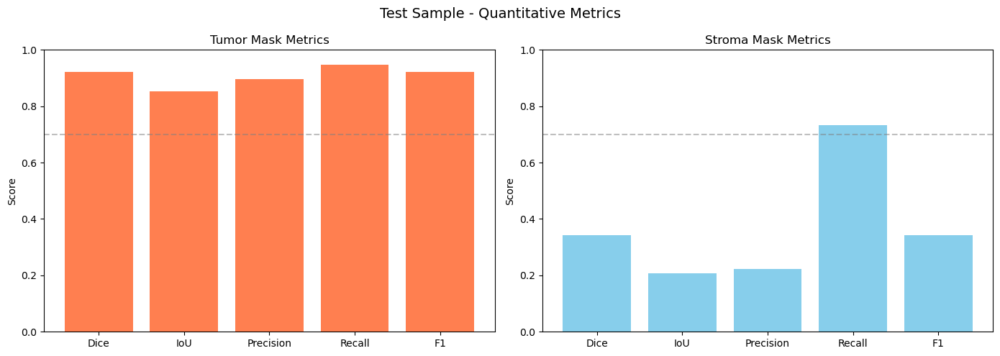

In [22]:
# Cell 8: Calculate Metrics
"""
Calculate all overlap metrics
"""

print("\n4. Calculating overlap metrics...")

metrics = calculate_overlap_metrics(
    pred_tumor=mask_tumor_reg,
    pred_stroma=mask_stroma_reg,
    ref_tumor=ref_tumor,
    ref_stroma=ref_stroma
)

# Display results
print("\n=== TUMOR METRICS ===")
print(f"  Dice coefficient: {metrics['dice_tumor']:.3f}")
print(f"  IoU (Jaccard):    {metrics['iou_tumor']:.3f}")
print(f"  Precision:        {metrics['precision_tumor']:.3f}")
print(f"  Recall:           {metrics['recall_tumor']:.3f}")
print(f"  F1 Score:         {metrics['f1_tumor']:.3f}")

print("\n=== STROMA METRICS ===")
print(f"  Dice coefficient: {metrics['dice_stroma']:.3f}")
print(f"  IoU (Jaccard):    {metrics['iou_stroma']:.3f}")
print(f"  Precision:        {metrics['precision_stroma']:.3f}")
print(f"  Recall:           {metrics['recall_stroma']:.3f}")
print(f"  F1 Score:         {metrics['f1_stroma']:.3f}")

print(f"\n=== OVERALL ===")
print(f"  Pixel Accuracy:   {metrics['pixel_accuracy']:.3f}")

# Visualize metrics
fig_metrics = plot_metrics_bar(metrics, sample_name="Test Sample")
plt.show()


5. Calculating marker enrichment...

=== MARKER ENRICHMENT ===
  mask       marker  mean_intensity  mean_outside  enrichment_ratio
 tumor    red_tumor        0.157050      0.042920          3.659104
 tumor green_stroma        0.032949      0.040723          0.809087
 tumor    blue_dapi        0.147070      0.093072          1.580174
stroma    red_tumor        0.038418      0.156075          0.246148
stroma green_stroma        0.041438      0.032737          1.265764
stroma    blue_dapi        0.093886      0.144603          0.649271


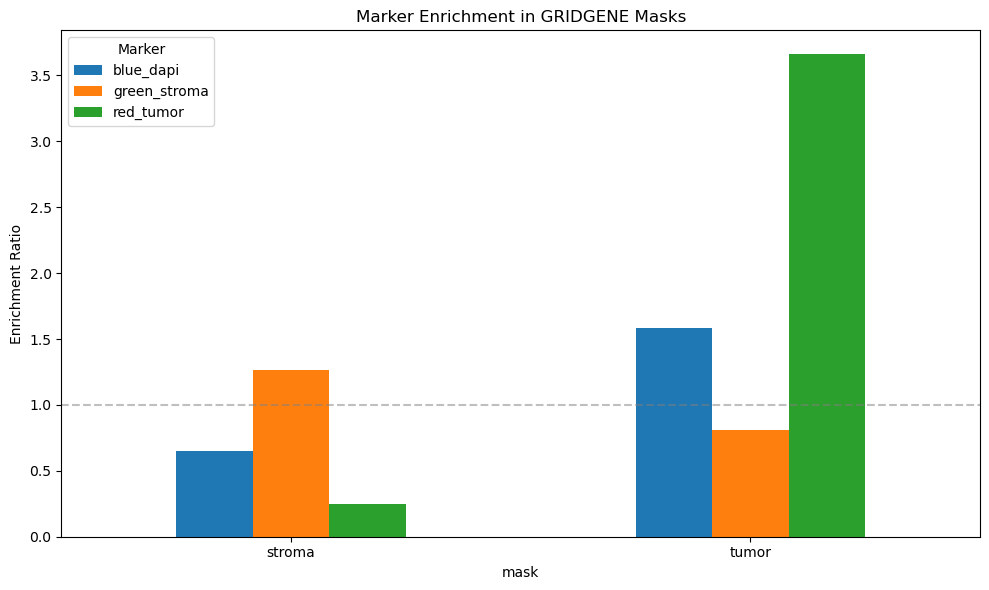

In [24]:
# Cell 9: Calculate Marker Enrichment
"""
Validate biological relevance - do tumor/stroma masks show expected marker enrichment?
"""

print("\n5. Calculating marker enrichment...")

enrichment_df = calculate_enrichment(
    masks={'tumor': mask_tumor_reg, 'stroma': mask_stroma_reg},
    marker_image=if_image,
    marker_names=['red_tumor', 'green_stroma', 'blue_dapi']
)

print("\n=== MARKER ENRICHMENT ===")
print(enrichment_df.to_string(index=False))

# Visualize enrichment
fig, ax = plt.subplots(figsize=(10, 6))
enrichment_pivot = enrichment_df.pivot(index='mask', columns='marker', values='enrichment_ratio')
enrichment_pivot.plot(kind='bar', ax=ax)
ax.set_ylabel('Enrichment Ratio')
ax.set_title('Marker Enrichment in GRIDGENE Masks')
ax.axhline(y=1.0, color='gray', linestyle='--', alpha=0.5)
ax.legend(title='Marker')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


5b. Validating empty regions...

=== MARKER INTENSITY IN ALL REGIONS ===
  mask       marker  mean_intensity  mean_outside  enrichment_ratio
 tumor    red_tumor        0.157050      0.042920          3.659104
 tumor green_stroma        0.032949      0.040723          0.809087
 tumor    blue_dapi        0.147070      0.093072          1.580174
stroma    red_tumor        0.038418      0.156075          0.246148
stroma green_stroma        0.041438      0.032737          1.265764
stroma    blue_dapi        0.093886      0.144603          0.649271
 empty    red_tumor        0.125116      0.108015          1.158330
 empty green_stroma        0.026844      0.036487          0.735707
 empty    blue_dapi        0.075548      0.125218          0.603332


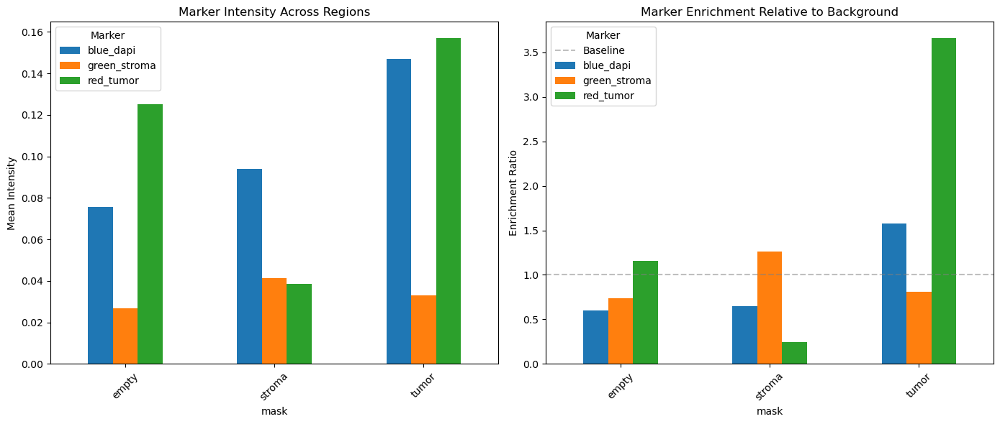


=== SUMMARY ===
red_tumor:
  Empty:  0.13
  Tumor:  0.16 (1.26x higher)
  Stroma: 0.04 (0.31x higher)
green_stroma:
  Empty:  0.03
  Tumor:  0.03 (1.23x higher)
  Stroma: 0.04 (1.54x higher)


In [31]:
# Cell 9b: Validate Empty Regions
"""
Check if GRIDGENE "empty" regions truly lack protein markers
"""

print("\n5b. Validating empty regions...")

# Calculate enrichment including empty regions
enrichment_with_empty = calculate_enrichment(
    masks={
        'tumor': mask_tumor_reg, 
        'stroma': mask_stroma_reg,
        'empty': mask_empty_reg  # ADDED
    },
    marker_image=if_image,
    marker_names=['red_tumor', 'green_stroma', 'blue_dapi']
)

print("\n=== MARKER INTENSITY IN ALL REGIONS ===")
print(enrichment_with_empty.to_string(index=False))

# Visualize - expect empty to have lowest intensity
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot 1: Mean intensities
enrichment_pivot = enrichment_with_empty.pivot(
    index='mask', columns='marker', values='mean_intensity'
)
enrichment_pivot.plot(kind='bar', ax=axes[0])
axes[0].set_ylabel('Mean Intensity')
axes[0].set_title('Marker Intensity Across Regions')
axes[0].legend(title='Marker')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45)

# Plot 2: Enrichment ratios
enrichment_pivot2 = enrichment_with_empty.pivot(
    index='mask', columns='marker', values='enrichment_ratio'
)
enrichment_pivot2.plot(kind='bar', ax=axes[1])
axes[1].set_ylabel('Enrichment Ratio')
axes[1].set_title('Marker Enrichment Relative to Background')
axes[1].axhline(y=1.0, color='gray', linestyle='--', alpha=0.5, label='Baseline')
axes[1].legend(title='Marker')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45)

plt.tight_layout()
plt.show()

# Summary statistics
print("\n=== SUMMARY ===")
for marker in ['red_tumor', 'green_stroma']:
    empty_val = enrichment_with_empty[
        (enrichment_with_empty['mask'] == 'empty') & 
        (enrichment_with_empty['marker'] == marker)
    ]['mean_intensity'].values[0]
    
    tumor_val = enrichment_with_empty[
        (enrichment_with_empty['mask'] == 'tumor') & 
        (enrichment_with_empty['marker'] == marker)
    ]['mean_intensity'].values[0]
    
    stroma_val = enrichment_with_empty[
        (enrichment_with_empty['mask'] == 'stroma') & 
        (enrichment_with_empty['marker'] == marker)
    ]['mean_intensity'].values[0]
    
    print(f"{marker}:")
    print(f"  Empty:  {empty_val:.2f}")
    print(f"  Tumor:  {tumor_val:.2f} ({tumor_val/empty_val:.2f}x higher)")
    print(f"  Stroma: {stroma_val:.2f} ({stroma_val/empty_val:.2f}x higher)")


6. Creating comprehensive comparison...


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..255.0].


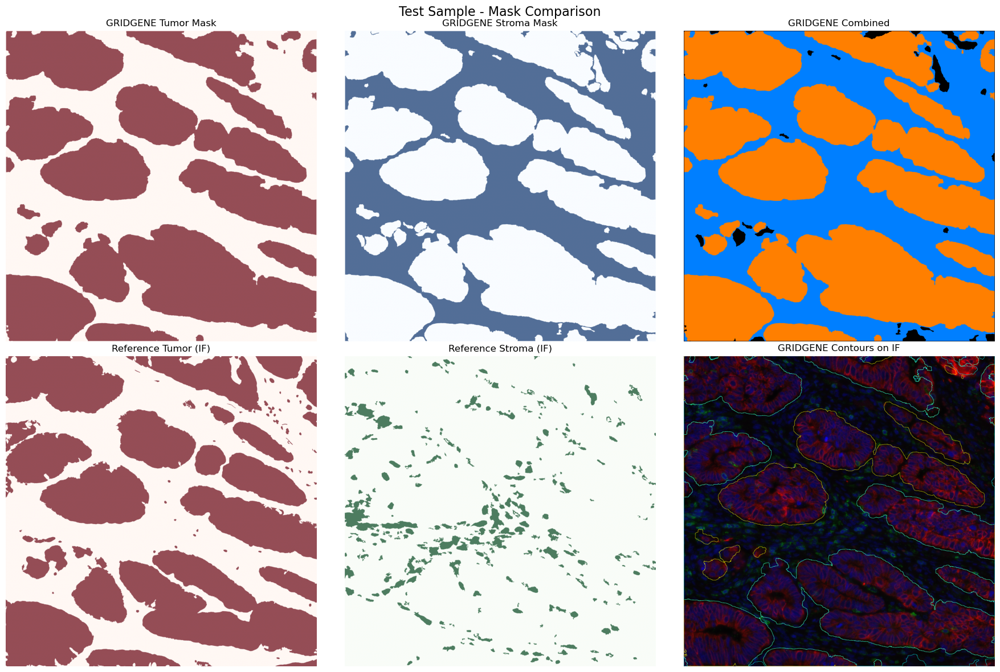

In [26]:
# Cell 10: Comprehensive Visualization
"""
Create final comparison figure
"""

print("\n6. Creating comprehensive comparison...")

fig_comparison = plot_mask_comparison(
    mask_tumor_reg, mask_stroma_reg,
    ref_tumor, ref_stroma,
    if_image=if_image,
    sample_name="Test Sample"
)
plt.show()

# # Save figure
# output_path = RESULTS_DIR / 'test_sample_comparison.png'
# fig_comparison.savefig(output_path, dpi=300, bbox_inches='tight')
# print(f"\n✓ Saved comparison figure to: {output_path}")

In [41]:
# FIXED: File Pairing Cell
"""
Match CosMx CSV files with corresponding IF composite images
"""

import os
import re
from natsort import natsorted

# === CosMx Files ===
cosmx_path_s0 = '/home/martinha/PycharmProjects/phd/spatial_transcriptomics/cosmx_data/S0/S0/20230628_151317_S4/AnalysisResults/iz38iruwno'

target_files_s0 = [
    os.path.join(cosmx_path_s0, folder, file)
    for folder in os.listdir(cosmx_path_s0)
    if os.path.isdir(os.path.join(cosmx_path_s0, folder))
    for file in os.listdir(os.path.join(cosmx_path_s0, folder))
    if '__target_call_coord.csv' in file
]
files_cosmx = natsorted(target_files_s0)

# === IF Files ===
if_composite_dir = '/home/martinha/PycharmProjects/phd/spatial_transcriptomics/GRIDGEN/case_studies/composites'
if_files = natsorted([
    os.path.join(if_composite_dir, f) 
    for f in os.listdir(if_composite_dir) 
    if f.endswith('_composite.tiff')
])

print(f"Found {len(files_cosmx)} CosMx files")
print(f"Found {len(if_files)} IF composite files")

# === FIXED: Extract FOV with different patterns ===
def extract_fov_number(filepath):
    """
    Extract FOV number from filename.
    Handles both FOV001 (CosMx) and F001 (IF) formats.
    Returns just the number as int.
    """
    # Try FOV001 pattern (CosMx)
    match = re.search(r'FOV(\d{3})', filepath)
    if match:
        return int(match.group(1))
    
    # Try F001 pattern (IF)
    match = re.search(r'F(\d{3})', filepath)
    if match:
        return int(match.group(1))
    
    return None

def extract_fov_id(filepath):
    """
    Extract standardized FOV ID (e.g., 'FOV001')
    """
    num = extract_fov_number(filepath)
    return f"FOV{num:03d}" if num is not None else None

# === Match files by FOV number ===
print("\n=== Matching files ===")
file_pairs = []

for cosmx_file in files_cosmx:
    fov_num = extract_fov_number(cosmx_file)
    if fov_num is not None:
        fov_id = f"FOV{fov_num:03d}"
        
        # Find matching IF file with same number
        matching_if = [f for f in if_files if extract_fov_number(f) == fov_num]
        
        if matching_if:
            file_pairs.append({
                'fov': fov_id,
                'fov_num': fov_num,
                'cosmx_csv': cosmx_file,
                'if_composite': matching_if[0]
            })
            print(f"✓ Matched {fov_id}: CosMx FOV{fov_num:03d} ↔ IF F{fov_num:03d}")
        else:
            print(f"✗ No IF match for FOV{fov_num:03d}")
    else:
        print(f"✗ Could not extract FOV from: {os.path.basename(cosmx_file)}")

print(f"\n✓ Total matched pairs: {len(file_pairs)}")

# Show first few pairs
if len(file_pairs) > 0:
    print("\nFirst 3 pairs:")
    for pair in file_pairs[:3]:
        print(f"  {pair['fov']}:")
        print(f"    CosMx: {os.path.basename(pair['cosmx_csv'])}")
        print(f"    IF:    {os.path.basename(pair['if_composite'])}")

Found 24 CosMx files
Found 24 IF composite files

=== Matching files ===
✓ Matched FOV001: CosMx FOV001 ↔ IF F001
✓ Matched FOV002: CosMx FOV002 ↔ IF F002
✓ Matched FOV003: CosMx FOV003 ↔ IF F003
✓ Matched FOV004: CosMx FOV004 ↔ IF F004
✓ Matched FOV005: CosMx FOV005 ↔ IF F005
✓ Matched FOV006: CosMx FOV006 ↔ IF F006
✓ Matched FOV007: CosMx FOV007 ↔ IF F007
✓ Matched FOV008: CosMx FOV008 ↔ IF F008
✓ Matched FOV009: CosMx FOV009 ↔ IF F009
✓ Matched FOV010: CosMx FOV010 ↔ IF F010
✓ Matched FOV011: CosMx FOV011 ↔ IF F011
✓ Matched FOV012: CosMx FOV012 ↔ IF F012
✓ Matched FOV013: CosMx FOV013 ↔ IF F013
✓ Matched FOV014: CosMx FOV014 ↔ IF F014
✓ Matched FOV015: CosMx FOV015 ↔ IF F015
✓ Matched FOV016: CosMx FOV016 ↔ IF F016
✓ Matched FOV017: CosMx FOV017 ↔ IF F017
✓ Matched FOV018: CosMx FOV018 ↔ IF F018
✓ Matched FOV019: CosMx FOV019 ↔ IF F019
✓ Matched FOV020: CosMx FOV020 ↔ IF F020
✓ Matched FOV021: CosMx FOV021 ↔ IF F021
✓ Matched FOV022: CosMx FOV022 ↔ IF F022
✓ Matched FOV023: CosMx F

In [42]:
# NEW CELL: Batch Processing (FIXED)
"""
Process all FOVs and collect metrics
"""

def process_single_fov(cosmx_csv, if_composite, fov_id, 
                       save_figures=True, fig_dir=None):
    """
    Process a single FOV and return metrics
    """
    try:
        # 1. Generate GRIDGENE masks
        mask_tumor_gg, mask_stroma_gg, mask_empty_gg, height, width = do_cosmx_pipeline(
            cosmx_csv, 
            target_tum=target_tum,
            kernel_size_tum=kernel_size_tum,
            density_th_tum=density_th_tum,
            min_area_th_tum=min_area_th_tum,
            kernel_size_empty=kernel_size_empty,
            density_th_empty=density_th_empty,
            min_area_th_empty=min_area_th_empty,
            plot=False  # Don't plot for batch
        )
        
        # 2. Create reference masks from IF
        ref_tumor, ref_stroma, metadata = preprocess_if_image(
            if_composite,
            red_percentile=red_percentile,
            green_percentile=green_percentile,
            min_area_tumor=min_area_tumor,
            min_area_stroma=min_area_stroma
        )
        
        # 3. Load IF image
        if_image = tifffile.imread(if_composite)
        
        # 4. Register masks
        mask_tumor_reg, mask_stroma_reg = register_masks_to_image(
            (mask_tumor_gg, mask_stroma_gg),
            if_image.shape,
            transpose=True
        )
        mask_empty_reg, _ = register_masks_to_image(
            (mask_empty_gg, mask_empty_gg),
            if_image.shape,
            transpose=True
        )
        
        # 5. Calculate metrics
        metrics = calculate_overlap_metrics(
            pred_tumor=mask_tumor_reg,
            pred_stroma=mask_stroma_reg,
            ref_tumor=ref_tumor,
            ref_stroma=ref_stroma
        )
        metrics['fov'] = fov_id
        
        # 6. Calculate enrichment
        enrichment = calculate_enrichment(
            masks={
                'tumor': mask_tumor_reg, 
                'stroma': mask_stroma_reg,
                'empty': mask_empty_reg
            },
            marker_image=if_image,
            marker_names=['red_tumor', 'green_stroma', 'blue_dapi']
        )
        
        # 7. Save figures if requested
        if save_figures and fig_dir:
            fig_comparison = plot_mask_comparison(
                mask_tumor_reg, mask_stroma_reg,
                ref_tumor, ref_stroma,
                if_image=if_image,
                sample_name=fov_id
            )
            fig_comparison.savefig(
                os.path.join(fig_dir, f'{fov_id}_comparison.png'),
                dpi=150, bbox_inches='tight'
            )
            plt.close(fig_comparison)
            
            fig_metrics = plot_metrics_bar(metrics, sample_name=fov_id)
            fig_metrics.savefig(
                os.path.join(fig_dir, f'{fov_id}_metrics.png'),
                dpi=150, bbox_inches='tight'
            )
            plt.close(fig_metrics)
        
        return metrics, enrichment, True, None
        
    except Exception as e:
        import traceback
        error_msg = f"{str(e)}\n{traceback.format_exc()}"
        print(f"  ✗ Error: {str(e)}")
        return None, None, False, error_msg


# Run batch processing
print("Processing all FOVs...")
print("=" * 60)

# Create output directory for figures - FIX: Use Path properly
from pathlib import Path
RESULTS_DIR = Path(RESULTS_DIR) if not isinstance(RESULTS_DIR, Path) else RESULTS_DIR
batch_fig_dir = RESULTS_DIR / 'batch_figures'
batch_fig_dir.mkdir(exist_ok=True, parents=True)

all_metrics = []
all_enrichment = []
failed_fovs = []

for i, pair in enumerate(tqdm(file_pairs), 1):
    print(f"\n{pair['fov']} ({i}/{len(file_pairs)})", end=" ")
    
    metrics, enrichment, success, error = process_single_fov(
        cosmx_csv=pair['cosmx_csv'],
        if_composite=pair['if_composite'],
        fov_id=pair['fov'],
        save_figures=True,
        fig_dir=str(batch_fig_dir)  # Convert Path to string
    )
    
    if success:
        all_metrics.append(metrics)
        enrichment['fov'] = pair['fov']
        all_enrichment.append(enrichment)
        print(f"✓ Dice (T/S): {metrics['dice_tumor']:.3f} / {metrics['dice_stroma']:.3f}")
    else:
        failed_fovs.append({'fov': pair['fov'], 'error': error})
        print(f"✗ FAILED")

print("\n" + "=" * 60)
print(f"✓ Successfully processed: {len(all_metrics)}/{len(file_pairs)} FOVs")

# Only create DataFrames if we have results
if len(all_metrics) > 0:
    df_metrics = pd.DataFrame(all_metrics)
    df_metrics.to_csv(RESULTS_DIR / 'cohort_metrics.csv', index=False)
    print(f"✓ Metrics saved to {RESULTS_DIR / 'cohort_metrics.csv'}")
else:
    print("✗ No successful FOVs - no metrics to save")
    df_metrics = None

if len(all_enrichment) > 0:
    df_enrichment = pd.concat(all_enrichment, ignore_index=True)
    df_enrichment.to_csv(RESULTS_DIR / 'cohort_enrichment.csv', index=False)
    print(f"✓ Enrichment saved to {RESULTS_DIR / 'cohort_enrichment.csv'}")
else:
    print("✗ No successful FOVs - no enrichment to save")
    df_enrichment = None

if failed_fovs:
    print(f"\n✗ Failed {len(failed_fovs)} FOVs:")
    for fail in failed_fovs[:5]:  # Show first 5
        print(f"  - {fail['fov']}")
        print(f"    Error: {fail['error'][:200]}...")  # First 200 chars
    if len(failed_fovs) > 5:
        print(f"  ... and {len(failed_fovs) - 5} more")
    
    # Save failed FOVs log
    with open(RESULTS_DIR / 'failed_fovs.txt', 'w') as f:
        for fail in failed_fovs:
            f.write(f"FOV: {fail['fov']}\n")
            f.write(f"Error: {fail['error']}\n")
            f.write("-" * 80 + "\n")
    print(f"✓ Failed FOVs log saved to {RESULTS_DIR / 'failed_fovs.txt'}")

print(f"\n✓ Results saved to {RESULTS_DIR}")

Processing all FOVs...


  0%|                                                                         | 0/24 [00:00<?, ?it/s]


FOV001 (1/24) 

2025-12-10 00:42:11,026 - gridgene.contours.tum - INFO - Initialized GetContour
2025-12-10 00:42:11,514 - gridgene.contours.tum - INFO - get_conv_sum took 0.4876 seconds
2025-12-10 00:42:11,832 - gridgene.contours.tum - INFO - Number of contours after filtering no counts: 38
2025-12-10 00:42:11,833 - gridgene.contours.tum - INFO - contours_from_sum took 0.3182 seconds
2025-12-10 00:42:11,833 - gridgene.contours.empty - INFO - Initialized GetContour
2025-12-10 00:42:20,535 - gridgene.contours.empty - INFO - get_conv_sum took 8.7010 seconds
2025-12-10 00:42:29,027 - gridgene.contours.empty - INFO - Number of contours after filtering no counts: 35
2025-12-10 00:42:29,027 - gridgene.contours.empty - INFO - contours_from_sum took 8.4922 seconds
2025-12-10 00:42:29,028 - gridgene.get_masks.GetMasks - INFO - Initialized GetMasks
2025-12-10 00:42:29,061 - gridgene.get_masks.GetMasks - INFO - Subtracted masks from base mask.
Clipping input data to the valid range for imshow with RGB data ([0..1

✓ Dice (T/S): 0.921 / 0.241

FOV002 (2/24) 

...

  ✗ Error: operands could not be broadcast together with shapes (4255,4256) (4256,4256) 
✗ FAILED

FOV023 (23/24) 

2025-12-10 00:56:18,804 - gridgene.contours.tum - INFO - Initialized GetContour
2025-12-10 00:56:19,302 - gridgene.contours.tum - INFO - get_conv_sum took 0.4977 seconds
2025-12-10 00:56:19,612 - gridgene.contours.tum - INFO - Number of contours after filtering no counts: 52
2025-12-10 00:56:19,612 - gridgene.contours.tum - INFO - contours_from_sum took 0.3097 seconds
2025-12-10 00:56:19,613 - gridgene.contours.empty - INFO - Initialized GetContour
2025-12-10 00:56:28,386 - gridgene.contours.empty - INFO - get_conv_sum took 8.7733 seconds
2025-12-10 00:56:37,072 - gridgene.contours.empty - INFO - Number of contours after filtering no counts: 139
2025-12-10 00:56:37,072 - gridgene.contours.empty - INFO - contours_from_sum took 8.6857 seconds
2025-12-10 00:56:37,073 - gridgene.get_masks.GetMasks - INFO - Initialized GetMasks
2025-12-10 00:56:37,100 - gridgene.get_masks.GetMasks - INFO - Subtracted masks from base mask.
Clipping input data to the valid range for imshow with RGB data ([0..

✓ Dice (T/S): 0.729 / 0.220

FOV024 (24/24) 

2025-12-10 00:56:59,790 - gridgene.contours.tum - INFO - Initialized GetContour
2025-12-10 00:57:00,296 - gridgene.contours.tum - INFO - get_conv_sum took 0.5054 seconds
2025-12-10 00:57:00,612 - gridgene.contours.tum - INFO - Number of contours after filtering no counts: 61
2025-12-10 00:57:00,613 - gridgene.contours.tum - INFO - contours_from_sum took 0.3165 seconds
2025-12-10 00:57:00,613 - gridgene.contours.empty - INFO - Initialized GetContour
2025-12-10 00:57:08,456 - gridgene.contours.empty - INFO - get_conv_sum took 7.8428 seconds
2025-12-10 00:57:16,135 - gridgene.contours.empty - INFO - Number of contours after filtering no counts: 103
2025-12-10 00:57:16,136 - gridgene.contours.empty - INFO - contours_from_sum took 7.6793 seconds
2025-12-10 00:57:16,137 - gridgene.get_masks.GetMasks - INFO - Initialized GetMasks
2025-12-10 00:57:16,166 - gridgene.get_masks.GetMasks - INFO - Subtracted masks from base mask.
Clipping input data to the valid range for imshow with RGB data ([0..

✓ Dice (T/S): 0.552 / 0.225

✓ Successfully processed: 22/24 FOVs
✓ Metrics saved to results/cohort_metrics.csv
✓ Enrichment saved to results/cohort_enrichment.csv

✗ Failed 2 FOVs:
  - FOV019
    Error: operands could not be broadcast together with shapes (4255,4256) (4256,4256) 
Traceback (most recent call last):
  File "/tmp/ipykernel_375384/2919513468.py", line 50, in process_single_fov
    metric...
  - FOV022
    Error: operands could not be broadcast together with shapes (4255,4256) (4256,4256) 
Traceback (most recent call last):
  File "/tmp/ipykernel_375384/2919513468.py", line 50, in process_single_fov
    metric...
✓ Failed FOVs log saved to results/failed_fovs.txt

✓ Results saved to results


=== COHORT SUMMARY STATISTICS ===

      dice_tumor  dice_stroma  iou_tumor  iou_stroma  precision_tumor  precision_stroma  recall_tumor  recall_stroma  f1_tumor  f1_stroma  pixel_accuracy
mean    0.630756     0.207588   0.515007    0.117687         0.964897          0.126595      0.537504       0.639566  0.630756   0.207588        0.527539
std     0.281260     0.075518   0.280652    0.046624         0.047265          0.050855      0.302850       0.222801  0.281260   0.075518        0.137084
min     0.044729     0.059915   0.022876    0.030882         0.816378          0.033885      0.022876       0.121759  0.044729   0.059915        0.210162
max     0.939748     0.347536   0.886345    0.210314         1.000000          0.249429      0.946471       0.917866  0.939748   0.347536        0.817609


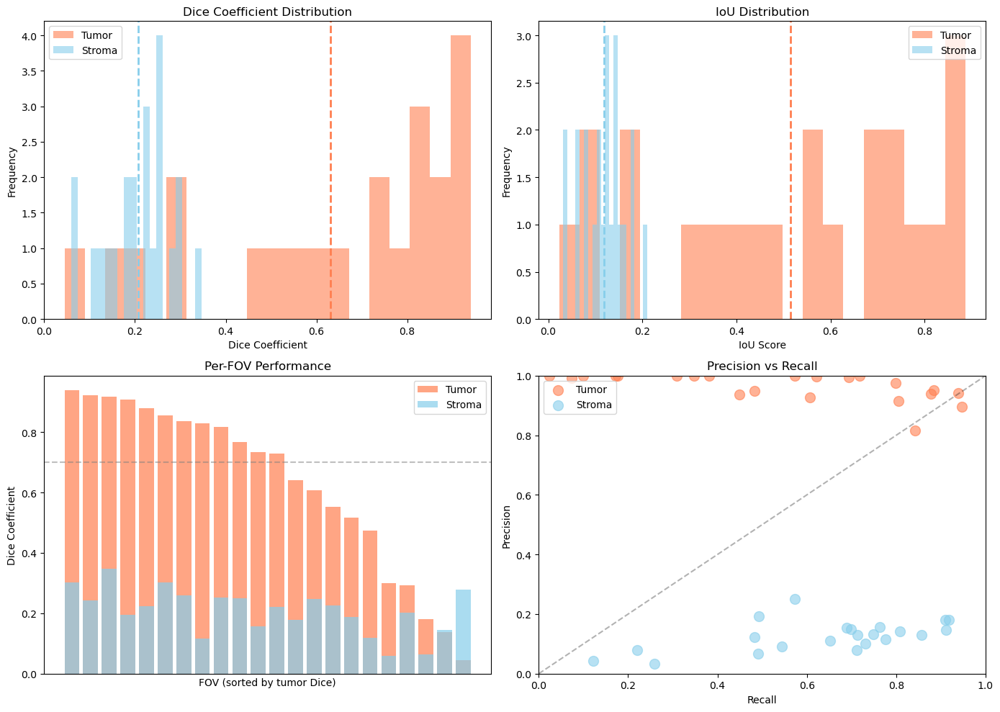


✓ Summary figure saved


In [43]:
# NEW CELL: Cohort Summary Statistics
"""
Aggregate statistics across all FOVs
"""

print("=== COHORT SUMMARY STATISTICS ===\n")

# Summary statistics for each metric
metrics_cols = ['dice_tumor', 'dice_stroma', 'iou_tumor', 'iou_stroma',
                'precision_tumor', 'precision_stroma', 'recall_tumor', 'recall_stroma',
                'f1_tumor', 'f1_stroma', 'pixel_accuracy']

summary = df_metrics[metrics_cols].describe().loc[['mean', 'std', 'min', 'max']]
print(summary.to_string())

# Create summary plots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Dice coefficients distribution
axes[0, 0].hist(df_metrics['dice_tumor'], bins=20, alpha=0.6, label='Tumor', color='coral')
axes[0, 0].hist(df_metrics['dice_stroma'], bins=20, alpha=0.6, label='Stroma', color='skyblue')
axes[0, 0].axvline(df_metrics['dice_tumor'].mean(), color='coral', linestyle='--', linewidth=2)
axes[0, 0].axvline(df_metrics['dice_stroma'].mean(), color='skyblue', linestyle='--', linewidth=2)
axes[0, 0].set_xlabel('Dice Coefficient')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].set_title('Dice Coefficient Distribution')
axes[0, 0].legend()

# Plot 2: IoU distribution
axes[0, 1].hist(df_metrics['iou_tumor'], bins=20, alpha=0.6, label='Tumor', color='coral')
axes[0, 1].hist(df_metrics['iou_stroma'], bins=20, alpha=0.6, label='Stroma', color='skyblue')
axes[0, 1].axvline(df_metrics['iou_tumor'].mean(), color='coral', linestyle='--', linewidth=2)
axes[0, 1].axvline(df_metrics['iou_stroma'].mean(), color='skyblue', linestyle='--', linewidth=2)
axes[0, 1].set_xlabel('IoU Score')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].set_title('IoU Distribution')
axes[0, 1].legend()

# Plot 3: Per-FOV metrics
fov_order = df_metrics.sort_values('dice_tumor', ascending=False)['fov']
x_pos = np.arange(len(fov_order))
axes[1, 0].bar(x_pos, df_metrics.set_index('fov').loc[fov_order, 'dice_tumor'], 
               alpha=0.7, color='coral', label='Tumor')
axes[1, 0].bar(x_pos, df_metrics.set_index('fov').loc[fov_order, 'dice_stroma'], 
               alpha=0.7, color='skyblue', label='Stroma')
axes[1, 0].axhline(y=0.7, color='gray', linestyle='--', alpha=0.5)
axes[1, 0].set_xlabel('FOV (sorted by tumor Dice)')
axes[1, 0].set_ylabel('Dice Coefficient')
axes[1, 0].set_title('Per-FOV Performance')
axes[1, 0].legend()
axes[1, 0].set_xticks([])  # Too many to label

# Plot 4: Precision vs Recall
axes[1, 1].scatter(df_metrics['recall_tumor'], df_metrics['precision_tumor'], 
                   alpha=0.6, s=100, color='coral', label='Tumor')
axes[1, 1].scatter(df_metrics['recall_stroma'], df_metrics['precision_stroma'], 
                   alpha=0.6, s=100, color='skyblue', label='Stroma')
axes[1, 1].plot([0, 1], [0, 1], 'k--', alpha=0.3)
axes[1, 1].set_xlabel('Recall')
axes[1, 1].set_ylabel('Precision')
axes[1, 1].set_title('Precision vs Recall')
axes[1, 1].legend()
axes[1, 1].set_xlim([0, 1])
axes[1, 1].set_ylim([0, 1])

plt.tight_layout()
plt.savefig(RESULTS_DIR / 'cohort_summary.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"\n✓ Summary figure saved")

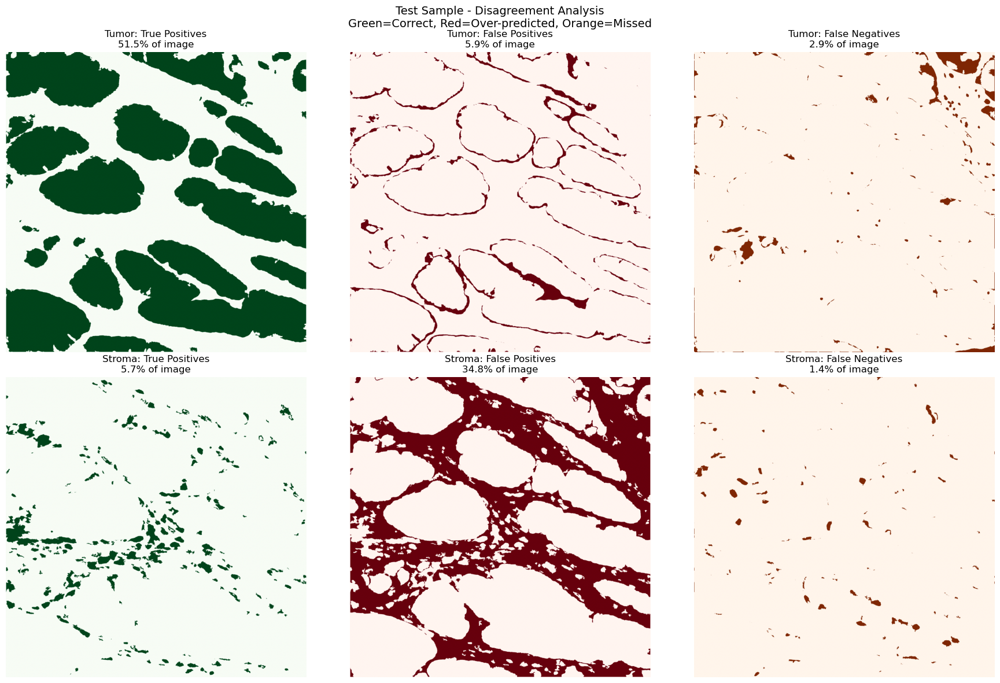


=== DISAGREEMENT SUMMARY ===
Tumor - Correct: 51.5%, Over: 5.9%, Missed: 2.9%
Stroma - Correct: 5.7%, Over: 34.8%, Missed: 1.4%


In [37]:
# NEW CELL: Disagreement Visualization
"""
Visualize where predictions disagree with reference
"""

from scripts.metrics import analyze_disagreement

def plot_disagreement_analysis(pred_tumor, pred_stroma, ref_tumor, ref_stroma, 
                               if_image=None, sample_name="Sample"):
    """
    Visualize confusion regions
    """
    
    disagreement = analyze_disagreement(pred_tumor, pred_stroma, ref_tumor, ref_stroma)
    
    fig, axes = plt.subplots(2, 3, figsize=(18, 12))
    
    # Row 1: Tumor confusion
    # True Positives (correct predictions)
    axes[0, 0].imshow(disagreement['masks']['tp_tumor'], cmap='Greens')
    axes[0, 0].set_title(f"Tumor: True Positives\n{disagreement['tp_tumor_pct']:.1f}% of image")
    axes[0, 0].axis('off')
    
    # False Positives (over-prediction)
    axes[0, 1].imshow(disagreement['masks']['fp_tumor'], cmap='Reds')
    axes[0, 1].set_title(f"Tumor: False Positives\n{disagreement['fp_tumor_pct']:.1f}% of image")
    axes[0, 1].axis('off')
    
    # False Negatives (under-prediction)
    axes[0, 2].imshow(disagreement['masks']['fn_tumor'], cmap='Oranges')
    axes[0, 2].set_title(f"Tumor: False Negatives\n{disagreement['fn_tumor_pct']:.1f}% of image")
    axes[0, 2].axis('off')
    
    # Row 2: Stroma confusion
    axes[1, 0].imshow(disagreement['masks']['tp_stroma'], cmap='Greens')
    axes[1, 0].set_title(f"Stroma: True Positives\n{disagreement['tp_stroma_pct']:.1f}% of image")
    axes[1, 0].axis('off')
    
    axes[1, 1].imshow(disagreement['masks']['fp_stroma'], cmap='Reds')
    axes[1, 1].set_title(f"Stroma: False Positives\n{disagreement['fp_stroma_pct']:.1f}% of image")
    axes[1, 1].axis('off')
    
    axes[1, 2].imshow(disagreement['masks']['fn_stroma'], cmap='Oranges')
    axes[1, 2].set_title(f"Stroma: False Negatives\n{disagreement['fn_stroma_pct']:.1f}% of image")
    axes[1, 2].axis('off')
    
    plt.suptitle(f'{sample_name} - Disagreement Analysis\nGreen=Correct, Red=Over-predicted, Orange=Missed', 
                 fontsize=14, y=0.98)
    plt.tight_layout()
    
    return fig, disagreement


# Test on single FOV
fig_disagree, disagree_stats = plot_disagreement_analysis(
    mask_tumor_reg, mask_stroma_reg,
    ref_tumor, ref_stroma,
    if_image=if_image,
    sample_name="Test Sample"
)
plt.show()

print("\n=== DISAGREEMENT SUMMARY ===")
print(f"Tumor - Correct: {disagree_stats['tp_tumor_pct']:.1f}%, "
      f"Over: {disagree_stats['fp_tumor_pct']:.1f}%, "
      f"Missed: {disagree_stats['fn_tumor_pct']:.1f}%")
print(f"Stroma - Correct: {disagree_stats['tp_stroma_pct']:.1f}%, "
      f"Over: {disagree_stats['fp_stroma_pct']:.1f}%, "
      f"Missed: {disagree_stats['fn_stroma_pct']:.1f}%")

In [7]:
file_csv = files_names[0]   # 5
df_total = pd.read_csv(file_csv)
df_total['X'] = (round(df_total['x'])).astype(int)
df_total['Y'] = (round(df_total['y'])).astype(int)

print('max x', max(df_total['x']))
print('max y', max(df_total['y']))
print('rounded max x', max(df_total['X']))
print('rounded max y', max(df_total['Y']))

print('df shape', df_total.shape)
print('df columns', df_total.columns)

df_total['target'].value_counts()

# remove Controls
df_total = df_total[~df_total['target'].str.contains('System|egative')]
n_genes = len(df_total['target'].unique())
height = max(df_total['X'] + 1)
width = max(df_total['Y'] + 1)

print(f'n genes: {n_genes}')
print(f'shape: {height}, {width}')
print(f'n hits {len(df_total)}')

# this makes the sparse df to an array with the spatial information 
target_dict_total = {target: index for index, target in enumerate(df_total['target'].unique())}
array_total = ga.transform_df_to_array(df = df_total, target_dict=target_dict_total, array_shape = (height, width,len(target_dict_total))).astype(np.int8)

# creating subsets 
df_subset_tum, array_subset_tum, target_indices_subset_tum = ga.get_subset_arrays(df_total, array_total,target_dict_total,
                                                                     target_list=target_tum, target_col = 'target')

max x 4245.27
max y 4245.32
rounded max x 4245
rounded max y 4245
df shape (1843019, 22)
df columns Index(['Unnamed: 0', 'Spot1_count', 'Spot2_count', 'Spot3_count',
       'Spot4_count', 'codeclass', 'fov', 'multicolor_spots_per_feature',
       'possible_BC_count', 'random_call_probability', 'seed_x', 'seed_y',
       'spots_per_feature', 'target', 'target_call_observations',
       'target_count_per_feature', 'target_idx', 'x', 'y', 'z', 'X', 'Y'],
      dtype='object')
n genes: 999
shape: 4246, 4246
n hits 1819904


2025-12-06 00:12:08,298 - gridgene.contours.tum - INFO - Initialized GetContour
2025-12-06 00:12:08,812 - gridgene.contours.tum - INFO - get_conv_sum took 0.5127 seconds
2025-12-06 00:12:09,188 - gridgene.contours.tum - INFO - Number of contours after filtering no counts: 38
2025-12-06 00:12:09,189 - gridgene.contours.tum - INFO - contours_from_sum took 0.3760 seconds
2025-12-06 00:12:09,189 - gridgene.contours.empty - INFO - Initialized GetContour
2025-12-06 00:12:16,490 - gridgene.contours.empty - INFO - get_conv_sum took 7.3002 seconds
2025-12-06 00:12:23,532 - gridgene.contours.empty - INFO - Number of contours after filtering no counts: 35
2025-12-06 00:12:23,533 - gridgene.contours.empty - INFO - contours_from_sum took 7.0425 seconds


====
N contours for tissue area 35
N contours for cancer 38


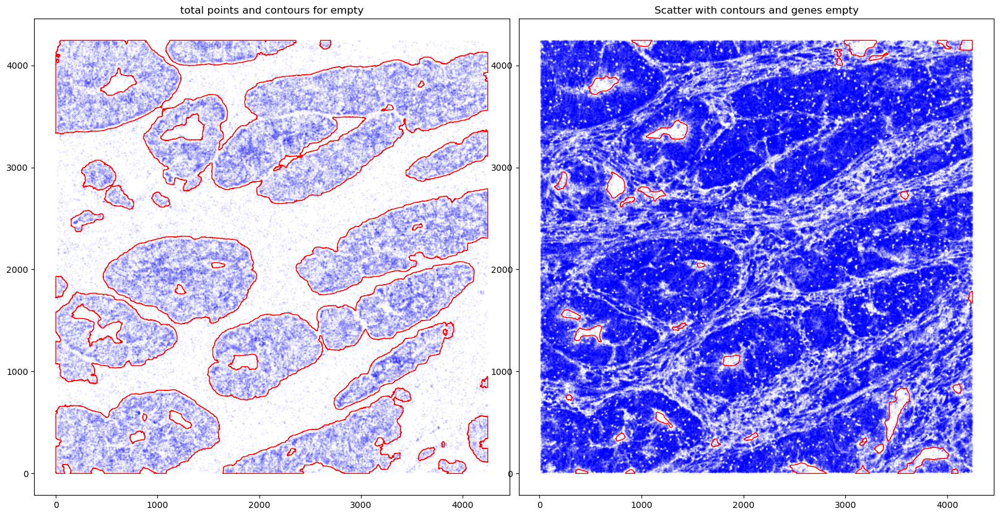

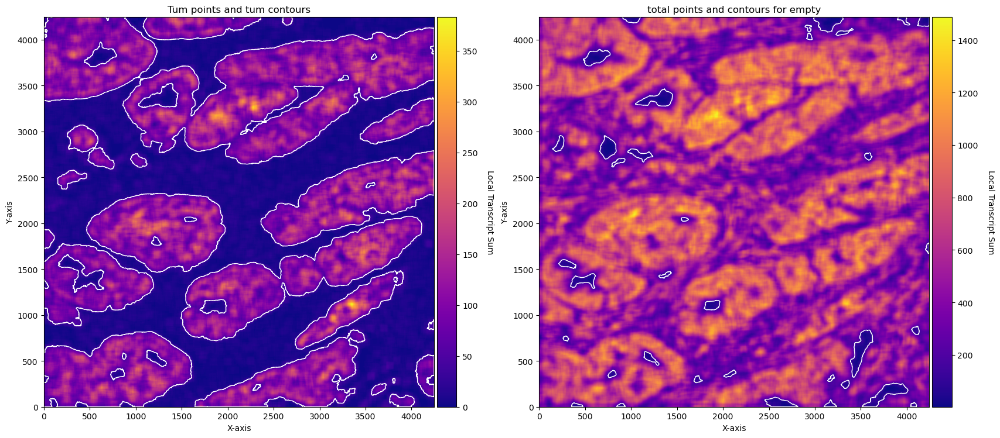

In [8]:
# obtain contours 
CTum = contours.ConvolutionContours(array_subset_tum, contour_name='tum')
CTum.get_conv_sum(kernel_size=kernel_size_tum, kernel_shape='square')
CTum.contours_from_sum(density_threshold = density_th_tum,
                       min_area_threshold = min_area_th_tum , directionality = 'higher')

CEmpty = contours.ConvolutionContours(array_total, contour_name='empty')
CEmpty.get_conv_sum(kernel_size=kernel_size_empty, kernel_shape='square')
CEmpty.contours_from_sum(density_threshold = density_th_empty,
                       min_area_threshold = min_area_th_empty, directionality = 'lower') # attention that directionality is lower here 


print('====')
print('N contours for tissue area', len(CEmpty.contours))
print('N contours for cancer', len(CTum.contours))

# PLOTs -- instead of plotting just with the function for example: CTum.plot_contours_scatter, we will make a composite image 

fig, axs = plt.subplots(1, 2, figsize=(20, 10))
CTum.plot_contours_scatter(path=None, show=False, s=0.05, alpha=0.5, linewidth=1,
                           c_points= 'blue',c_contours= 'red', ax=axs[0])
axs[0].set_title('Tum points and tum contours')  


CEmpty.plot_contours_scatter(path=None, show=False, s=0.05, alpha=0.5, linewidth=1,
                           c_points= 'blue',c_contours= 'red', ax=axs[1])
axs[0].set_title('total points and contours for empty')  
plt.subplots_adjust(wspace=0.02)  # Adjust to your preference

plt.show()
   

fig, axs = plt.subplots(1, 2, figsize=(20, 10))

CTum.plot_conv_sum(cmap='plasma', c_countour='white', ax=axs[0])
axs[0].set_title('Tum points and tum contours')

CEmpty.plot_conv_sum(cmap='plasma', c_countour='white', ax=axs[1])
axs[1].set_title('total points and contours for empty')

plt.show()

2025-12-06 00:12:34,161 - gridgene.get_masks.GetMasks - INFO - Initialized GetMasks
2025-12-06 00:12:34,199 - gridgene.get_masks.GetMasks - INFO - Subtracted masks from base mask.


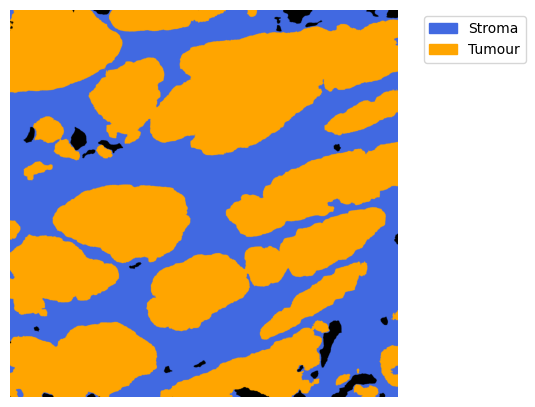

In [9]:
#### obtain masks
GM = get_masks.GetMasks(image_shape = (height, width))

mask_empty = GM.create_mask(CEmpty.contours)
mask_tum = GM.create_mask(CTum.contours)
mask_tum = GM.fill_holes(mask_tum)
mask_stroma = GM.subtract_masks(np.ones((height, width), dtype=np.uint8), mask_tum, mask_empty)          
mask_stroma = GM.filter_binary_mask_by_area(mask_stroma, min_area=700)

GM.plot_masks(masks=[mask_stroma, mask_tum], mask_names=['Stroma', 'Tumour'],
              background_color=(1, 1, 1), mask_colors={'Stroma': (65, 105, 225), 'Tumour': (255, 165, 0)},
              path=None, show=True, ax=None, figsize=(5, 6))

Overlay contours with ground truth

Just as an example, We will overlay this mask with the correspondent immunofluorescent image. In the IF image, nucleus are coloured with DAPI blue, cancer with red and the remaining membranes with green. For the lines, yellow represent the stroma contours and white cancer contours.

It's possible to see a very good overlap between regions.

Some discrepancies may be due to problems in the IF imaging and the non complete alignment as the IF and the CosMx are made on consecutive slides.

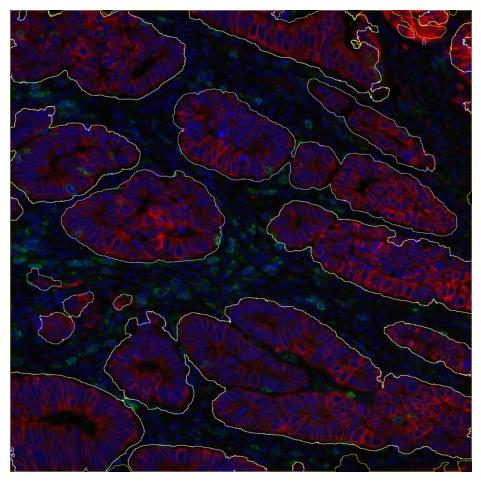

In [11]:
image = tiff.imread('/home/martinha/PycharmProjects/phd/spatial_transcriptomics/GRIDGEN/case_studies/composites/20230628_151317_S4_C902_P99_N99_F001_composite.tiff')

# Calculate the padding needed on each side
pad_y = (image.shape[1] - mask_stroma.shape[1]) // 2
pad_x = (image.shape[0] - mask_stroma.shape[0]) // 2

# Pad the mask with 5 pixels on each side to match the image size
# Here, we assume a binary mask, so we pad with 0s
mask1 = np.pad(mask_stroma, ((pad_y, pad_y), (pad_x, pad_x)), mode='constant', constant_values=0)
mask2 = np.pad(mask_tum, ((pad_y, pad_y), (pad_x, pad_x)), mode='constant', constant_values=0)

# mask1 = np.flip(mask1, axis = 0) 
mask1 = np.transpose(mask1)
mask2 = np.transpose(mask2)
image = (image * 255).astype(np.uint8)

# Create a copy of the image to overlay borders
image_with_contours = image.copy()

# Find contours for each mask
contours1, _ = cv2.findContours(mask1.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
contours2, _ = cv2.findContours(mask2.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

# Define colors for each mask's contours (Yellow for mask1, Cyan for mask2)
contour_color1 = (255, 255, 0)  # Yellow
contour_color2 = (255, 255, 255)  # Cyan

# Draw the contours on the image
cv2.drawContours(image_with_contours, contours1, -1, contour_color1, thickness=2)
cv2.drawContours(image_with_contours, contours2, -1, contour_color2, thickness=2)

# Plot the image with contours
plt.figure(figsize=(6, 6))  # Increase the figure size to make it larger
plt.imshow(image_with_contours)
plt.axis('off')  # Hide axes for cleaner visualization
plt.show()

In [ ]:
def do_cosmx_pipeline(file_csv):
    df_total = pd.read_csv(file_csv)
    df_total['X'] = (round(df_total['x'])).astype(int)
    df_total['Y'] = (round(df_total['y'])).astype(int)
    n_genes = len(df_total['target'].unique())
    height = max(df_total['X'] + 1)
    width = max(df_total['Y'] + 1)
    target_dict_total = {target: index for index, target in enumerate(df_total['target'].unique())}
    array_total = ga.transform_df_to_array(df = df_total, target_dict=target_dict_total, array_shape = (height, width,len(target_dict_total))).astype(np.int8)
    df_subset_tum, array_subset_tum, target_indices_subset_tum = ga.get_subset_arrays(df_total, array_total,target_dict_total,
                                                                         target_list=target_tum, target_col = 'target')
    
    # obtain contours 
    CTum = contours.ConvolutionContours(array_subset_tum, contour_name='tum')
    CTum.get_conv_sum(kernel_size=kernel_size_tum, kernel_shape='square')
    CTum.contours_from_sum(density_threshold = density_th_tum,
                           min_area_threshold = min_area_th_tum , directionality = 'higher')
    
    CEmpty = contours.ConvolutionContours(array_total, contour_name='empty')
    CEmpty.get_conv_sum(kernel_size=kernel_size_empty, kernel_shape='square')
    CEmpty.contours_from_sum(density_threshold = density_th_empty,
                           min_area_threshold = min_area_th_empty, directionality = 'lower') # attention that directionality is lower here 

        

    #### obtain masks
    GM = get_masks.GetMasks(image_shape = (height, width))
    
    mask_empty = GM.create_mask(CEmpty.contours)
    mask_tum = GM.create_mask(CTum.contours)
    mask_tum = GM.fill_holes(mask_tum)
    mask_stroma = GM.subtract_masks(np.ones((height, width), dtype=np.uint8), mask_tum, mask_empty)          
    mask_stroma = GM.filter_binary_mask_by_area(mask_stroma, min_area=700)
        
        
    fig, axs = plt.subplots(1, 3, figsize=(26, 8))
    CTum.plot_contours_scatter(path=None, show=False, s=0.05, alpha=0.5, linewidth=1,
                               c_points= 'blue',c_contours= 'red', ax=axs[0])
    axs[0].set_title('Tum points and tum contours')  
    
    
    CEmpty.plot_contours_scatter(path=None, show=False, s=0.05, alpha=0.5, linewidth=1,
                               c_points= 'blue',c_contours= 'red', ax=axs[1])
    axs[1].set_title('total points and contours for empty')  
    plt.subplots_adjust(wspace=0.02)  # Adjust to your preference
    
    GM.plot_masks(masks=[mask_stroma, mask_tum], mask_names=['Stroma', 'Tumour'],
                  background_color=(1, 1, 1), mask_colors={'Stroma': (65, 105, 225), 'Tumour': (255, 165, 0)},
                  path=None, show=False, ax=axs[2])
    axs[2].set_title('Masks')  

    plt.show()

In [ ]:
%%time

files_names = natsorted(target_files_s0)


for file_csv in tqdm(random.sample(files_names, 5)):
    do_cosmx_pipeline(file_csv)

## Xenium 

Map the 3 cores we have pairs IMC - Xenium

Read the IMC files

Perguntar se os IMC files estão clean! ou se vou ter de fazer ue os parametros! 
tgfbeta 40 0.2 

In [ ]:
Supplementary Table 1 - Thresholds and percentile values for the 39 IMC markers
Marker	Percentile	Threshold	Marker	Percentile	Threshold
B catenin	60	0.2	CD8a	60	0.25
CD103	30	0.1	cleavedcaspase	40	0.3
CD11b	50	0.25	D2-40	50	0.25
CD11c	40	0	FOXP3	50	0.1
CD14	40	0.1	Granzyme B	40	0.2
CD15	40	0.25	HLA-DR	50	0.1
CD163	40	0.3	ICOS	50	0.1
CD20	50	0.1	IDO	30	0.3
CD204	50	0.1	Keratin	50	0.5
CD3	50	0.1	Ki-67	50	0.2
CD31	50	0,2	P16ink4a	50	0.2
CD38	40	0.2	PD-1	40	0.2
CD39	40	0.2	PD-L1	50	0.3
CD4	50	0.2	Tbet	60	0.1
CD45 	50	0.2	TCRgd	40	0.1
CD45RO	50	0.2	TGFbeta	40	0.2
CD56	50	0.2	Vimentin	40	0.1
CD57	60	0.2	VISTA	50	0.2
CD68	40	0.2	CD7	50	0.2


In [ ]:
fetch the data for these rois
cretae masks

In [ ]:
METRICS

Compare masks to cell segmentation :

        CosMx cell segmentation
        Xenium cell segmentation
        
        CosMx masks
        Xenium masks 
        